In [5]:
from pathlib import Path
import wandb

ROOT = Path(
    r"C:\Local D\Galeri Belajar\Skripsi"
).resolve()

CHECKPOINT_DIR = (
    ROOT
    / "checkpoints"
    / "baseline"
    / "seed42_v38"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# ============================================================
# DOWNLOAD EXACT W&B ARTIFACT
# ============================================================

api = wandb.Api()

artifact = api.artifact(
    "ilhamrafiqin-brawijaya-university/"
    "skripsi-yolo26n-indotraffic/"
    "yolo26n-seed-42-checkpoint:v38",
    type="model",
)

artifact_dir = Path(
    artifact.download(
        root=str(CHECKPOINT_DIR)
    )
).resolve()

print(
    "Artifact directory:",
    artifact_dir,
)


# ============================================================
# FIND BEST.PT
# ============================================================

best_candidates = sorted(
    artifact_dir.rglob("best.pt")
)

print(
    "\nbest.pt candidates:"
)

for path in best_candidates:
    print(path)

if len(best_candidates) != 1:
    raise RuntimeError(
        "Expected exactly one best.pt, "
        f"found {len(best_candidates)}"
    )

BEST_PT = best_candidates[0]

print(
    "\nBASELINE CHECKPOINT:",
    BEST_PT,
)

wandb:   1 of 1 files downloaded.  


Artifact directory: C:\Local D\Galeri Belajar\Skripsi\checkpoints\baseline\seed42_v38

best.pt candidates:
C:\Local D\Galeri Belajar\Skripsi\checkpoints\baseline\seed42_v38\best.pt

BASELINE CHECKPOINT: C:\Local D\Galeri Belajar\Skripsi\checkpoints\baseline\seed42_v38\best.pt


In [6]:
# ============================================================
# STEP 1 — BASELINE CHECKPOINT IDENTITY GATE
# ============================================================

from pathlib import Path
import hashlib
import torch

from ultralytics import YOLO


# ============================================================
# EXPECTED BASELINE IDENTITY
# ============================================================

EXPECTED_NAMES = [
    "Bus",
    "Mobil Penumpang",
    "Pejalan Kaki",
    "Sepeda Motor",
    "Truck",
    "Unmotorized",
]

EXPECTED_NC = 6
EXPECTED_DETECT_SOURCES = [16, 19, 22]
EXPECTED_IMGSZ = 640


# ============================================================
# 1. CHECKPOINT FILE
# ============================================================

BEST_PT = Path(
    BEST_PT
).resolve()

if not BEST_PT.exists():
    raise FileNotFoundError(
        f"Checkpoint tidak ditemukan:\n{BEST_PT}"
    )

if BEST_PT.suffix.lower() != ".pt":
    raise ValueError(
        f"Checkpoint bukan file .pt: {BEST_PT}"
    )


def sha256_file(
    path,
    chunk_size=1024 * 1024,
):
    hasher = hashlib.sha256()

    with open(path, "rb") as file:
        while True:
            chunk = file.read(
                chunk_size
            )

            if not chunk:
                break

            hasher.update(
                chunk
            )

    return hasher.hexdigest()


CHECKPOINT_SHA256 = sha256_file(
    BEST_PT
)

CHECKPOINT_SIZE_MB = (
    BEST_PT.stat().st_size
    / 1024**2
)

print(
    "========================================"
)
print(
    "CHECKPOINT FILE"
)
print(
    "========================================"
)

print(
    "Path   :",
    BEST_PT,
)

print(
    "Size MB:",
    f"{CHECKPOINT_SIZE_MB:.2f}",
)

print(
    "SHA256 :",
    CHECKPOINT_SHA256,
)


# ============================================================
# 2. LOAD YOLO
# ============================================================

model = YOLO(
    str(BEST_PT)
)

core_model = model.model


# ============================================================
# 3. CLASS IDENTITY
# ============================================================

raw_names = model.names

if isinstance(
    raw_names,
    dict,
):
    checkpoint_names = [
        raw_names[k]
        for k in sorted(
            raw_names,
            key=lambda x: int(x),
        )
    ]

else:
    checkpoint_names = list(
        raw_names
    )


print(
    "\n========================================"
)
print(
    "CLASS IDENTITY"
)
print(
    "========================================"
)

print(
    "Classes:",
    checkpoint_names,
)

assert checkpoint_names == EXPECTED_NAMES, (
    "Class names/order berbeda.\n"
    f"Expected: {EXPECTED_NAMES}\n"
    f"Found   : {checkpoint_names}"
)


# ============================================================
# 4. DETECTION HEAD IDENTITY
# ============================================================

if not hasattr(
    core_model,
    "model",
):
    raise RuntimeError(
        "Internal model structure tidak dikenali."
    )

detect_layer = core_model.model[-1]

print(
    "\n========================================"
)
print(
    "DETECTION HEAD"
)
print(
    "========================================"
)

print(
    "Layer type:",
    detect_layer.__class__.__name__,
)

if detect_layer.__class__.__name__ != "Detect":
    raise RuntimeError(
        "Layer terakhir bukan Detect.\n"
        f"Found: {detect_layer.__class__.__name__}"
    )


detect_nc = getattr(
    detect_layer,
    "nc",
    None,
)

detect_sources = getattr(
    detect_layer,
    "f",
    None,
)

if detect_sources is not None:
    if isinstance(
        detect_sources,
        int,
    ):
        detect_sources = [
            detect_sources
        ]

    else:
        detect_sources = list(
            detect_sources
        )


print(
    "Detect nc     :",
    detect_nc,
)

print(
    "Detect sources:",
    detect_sources,
)


assert detect_nc == EXPECTED_NC, (
    f"Expected nc={EXPECTED_NC}, "
    f"found nc={detect_nc}"
)

assert detect_sources == EXPECTED_DETECT_SOURCES, (
    "Detect source layers berbeda.\n"
    f"Expected: {EXPECTED_DETECT_SOURCES}\n"
    f"Found   : {detect_sources}"
)


# ============================================================
# 5. MODEL FORWARD SANITY CHECK
# ============================================================

print(
    "\n========================================"
)
print(
    "FORWARD SANITY CHECK"
)
print(
    "========================================"
)

original_device = next(
    core_model.parameters()
).device

core_model.eval()

dummy = torch.zeros(
    1,
    3,
    EXPECTED_IMGSZ,
    EXPECTED_IMGSZ,
    device=original_device,
)

with torch.inference_mode():
    output = core_model(
        dummy
    )

print(
    "Input shape :",
    tuple(dummy.shape),
)

print(
    "Forward     : PASSED"
)

print(
    "Output type :",
    type(output).__name__,
)


# release dummy
del dummy
del output

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================
# 6. FINAL IDENTITY REPORT
# ============================================================

BASELINE_IDENTITY = {
    "checkpoint": str(
        BEST_PT
    ),
    "checkpoint_sha256": (
        CHECKPOINT_SHA256
    ),
    "checkpoint_size_mb": (
        CHECKPOINT_SIZE_MB
    ),
    "classes": (
        checkpoint_names
    ),
    "nc": detect_nc,
    "detect_sources": (
        detect_sources
    ),
    "evaluation_imgsz": (
        EXPECTED_IMGSZ
    ),
}


print(
    "\n========================================"
)

print(
    "BASELINE IDENTITY GATE: PASSED"
)

print(
    "========================================"
)

print(
    f"Classes        : {len(checkpoint_names)}"
)

print(
    f"Detect nc      : {detect_nc}"
)

print(
    f"Detect sources : {detect_sources}"
)

print(
    f"Forward        : "
    f"1×3×{EXPECTED_IMGSZ}×{EXPECTED_IMGSZ} ✓"
)

print(
    f"SHA256         : {CHECKPOINT_SHA256}"
)

CHECKPOINT FILE
Path   : C:\Local D\Galeri Belajar\Skripsi\checkpoints\baseline\seed42_v38\best.pt
Size MB: 5.12
SHA256 : 942bcd54f4029b74325a7ecfb80a226d8d4c030855ce1834091922905a59f0d1

CLASS IDENTITY
Classes: ['Bus', 'Mobil Penumpang', 'Pejalan Kaki', 'Sepeda Motor', 'Truck', 'Unmotorized']

DETECTION HEAD
Layer type: Detect
Detect nc     : 6
Detect sources: [16, 19, 22]

FORWARD SANITY CHECK
Input shape : (1, 3, 640, 640)
Forward     : PASSED
Output type : tuple

BASELINE IDENTITY GATE: PASSED
Classes        : 6
Detect nc      : 6
Detect sources : [16, 19, 22]
Forward        : 1×3×640×640 ✓
SHA256         : 942bcd54f4029b74325a7ecfb80a226d8d4c030855ce1834091922905a59f0d1


In [9]:
from pathlib import Path

ROOT = Path(
    r"C:\Local D\Galeri Belajar\Skripsi"
).resolve()

DATA_ROOT = ROOT / "data" / "audited_v2"

VAL_IMAGES = DATA_ROOT / "valid" / "images"
VAL_LABELS = DATA_ROOT / "valid" / "labels"

print("VAL_IMAGES:", VAL_IMAGES)
print("VAL_LABELS:", VAL_LABELS)

assert VAL_IMAGES.exists()
assert VAL_LABELS.exists()

print("Images:", len(list(VAL_IMAGES.glob("*"))))
print("Labels:", len(list(VAL_LABELS.glob("*.txt"))))

VAL_IMAGES: C:\Local D\Galeri Belajar\Skripsi\data\audited_v2\valid\images
VAL_LABELS: C:\Local D\Galeri Belajar\Skripsi\data\audited_v2\valid\labels
Images: 1790
Labels: 1790


In [11]:
# ============================================================
# STEP 2 — VALIDATION LABEL NORMALIZATION + DATASET GATE
# ============================================================

from pathlib import Path
import shutil

VAL_IMAGES = Path(VAL_IMAGES)
VAL_LABELS = Path(VAL_LABELS)

BACKUP_DIR = (
    VAL_LABELS.parent
    / "labels_before_failure_analysis_fix"
)

# ------------------------------------------------------------
# Backup label asli sekali saja
# ------------------------------------------------------------

if not BACKUP_DIR.exists():
    shutil.copytree(
        VAL_LABELS,
        BACKUP_DIR,
    )
    print("Backup dibuat:", BACKUP_DIR)
else:
    print("Backup sudah ada:", BACKUP_DIR)


# ------------------------------------------------------------
# Polygon -> enclosing bounding box
# ------------------------------------------------------------

def polygon_to_bbox(parts):
    cls = int(float(parts[0]))

    coords = list(
        map(float, parts[1:])
    )

    if (
        len(coords) < 6
        or len(coords) % 2 != 0
    ):
        raise ValueError(
            "Polygon tidak valid."
        )

    xs = coords[0::2]
    ys = coords[1::2]

    x1 = max(0.0, min(xs))
    y1 = max(0.0, min(ys))
    x2 = min(1.0, max(xs))
    y2 = min(1.0, max(ys))

    if x2 <= x1 or y2 <= y1:
        raise ValueError(
            "Polygon menghasilkan bbox tanpa area."
        )

    xc = (x1 + x2) / 2
    yc = (y1 + y2) / 2
    w = x2 - x1
    h = y2 - y1

    return (
        f"{cls} "
        f"{xc:.10f} "
        f"{yc:.10f} "
        f"{w:.10f} "
        f"{h:.10f}"
    )


converted_rows = []

for label_path in sorted(
    VAL_LABELS.glob("*.txt")
):
    raw = label_path.read_text(
        encoding="utf-8"
    ).strip()

    if not raw:
        continue

    new_lines = []
    changed = False

    for line_number, line in enumerate(
        raw.splitlines(),
        start=1,
    ):
        parts = line.split()

        # Bounding-box normal
        if len(parts) == 5:
            new_lines.append(line)
            continue

        # YOLO segmentation polygon
        if (
            len(parts) > 5
            and (len(parts) - 1) % 2 == 0
        ):
            new_line = polygon_to_bbox(
                parts
            )

            new_lines.append(
                new_line
            )

            converted_rows.append({
                "file": label_path.name,
                "line": line_number,
            })

            changed = True
            continue

        raise ValueError(
            "Format annotation tidak dikenali:\n"
            f"{label_path}\n"
            f"line {line_number}: {line}"
        )

    if changed:
        label_path.write_text(
            "\n".join(new_lines) + "\n",
            encoding="utf-8",
        )


# ------------------------------------------------------------
# Final validation gate
# ------------------------------------------------------------

image_exts = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
}

images = sorted(
    p
    for p in VAL_IMAGES.iterdir()
    if p.is_file()
    and p.suffix.lower() in image_exts
)

labels = sorted(
    VAL_LABELS.glob("*.txt")
)

annotation_count = 0
empty_count = 0
invalid_format = 0
polygon_remaining = 0


for label_path in labels:
    text = label_path.read_text(
        encoding="utf-8"
    ).strip()

    if not text:
        empty_count += 1
        continue

    for line in text.splitlines():
        annotation_count += 1

        parts = line.split()

        if len(parts) > 5:
            polygon_remaining += 1
            invalid_format += 1

        elif len(parts) != 5:
            invalid_format += 1


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("VALIDATION DATASET REPORT")
print("=" * 60)

print(
    "Polygon converted :",
    len(converted_rows),
)

for row in converted_rows:
    print(
        "  -",
        row["file"],
        "line",
        row["line"],
    )

print()
print("Images             :", len(images))
print("Labels             :", len(labels))
print("Annotations        :", annotation_count)
print("Empty labels       :", empty_count)
print("Polygon remaining  :", polygon_remaining)
print("Invalid format     :", invalid_format)


# ------------------------------------------------------------
# Hard gate
# ------------------------------------------------------------

assert len(images) == 1790
assert len(labels) == 1790
assert annotation_count == 32076
assert empty_count == 2
assert polygon_remaining == 0
assert invalid_format == 0

print("\nVALIDATION DATASET GATE: PASSED")

Backup dibuat: C:\Local D\Galeri Belajar\Skripsi\data\audited_v2\valid\labels_before_failure_analysis_fix

VALIDATION DATASET REPORT
Polygon converted : 4
  - Screenshot-2025-05-30-at-10_11_28_png.rf.ef69612a5e131f49cb22faeadbfd93c8.txt line 1
  - Screenshot-2025-05-30-at-10_11_28_png.rf.ef69612a5e131f49cb22faeadbfd93c8.txt line 2
  - Screenshot-2025-05-30-at-10_12_39_png.rf.ade7f4b47e05eba694820d45fd52c116.txt line 1
  - Screenshot-2025-05-30-at-10_12_39_png.rf.ade7f4b47e05eba694820d45fd52c116.txt line 2

Images             : 1790
Labels             : 1790
Annotations        : 32076
Empty labels       : 2
Polygon remaining  : 0
Invalid format     : 0

VALIDATION DATASET GATE: PASSED


In [12]:
# ============================================================
# STEP 3A — DISTRIBUSI KELAS PADA VALIDATION SET
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

CLASS_NAMES = [
    "Bus",
    "Mobil Penumpang",
    "Pejalan Kaki",
    "Sepeda Motor",
    "Truck",
    "Unmotorized",
]

class_counts = {
    i: 0
    for i in range(len(CLASS_NAMES))
}

total_annotations = 0

for label_path in sorted(VAL_LABELS.glob("*.txt")):
    text = label_path.read_text(
        encoding="utf-8"
    ).strip()

    if not text:
        continue

    for line in text.splitlines():
        parts = line.split()

        cls = int(
            float(parts[0])
        )

        class_counts[cls] += 1
        total_annotations += 1


class_df = pd.DataFrame({
    "Class ID": range(len(CLASS_NAMES)),
    "Class": CLASS_NAMES,
    "Annotations": [
        class_counts[i]
        for i in range(len(CLASS_NAMES))
    ],
})

class_df["Percentage"] = (
    class_df["Annotations"]
    / total_annotations
    * 100
)

display(
    class_df.style.format({
        "Percentage": "{:.2f}%"
    })
)

print(
    "Total annotations:",
    total_annotations,
)

assert total_annotations == 32076

,Class ID,Class,Annotations,Percentage
0,0,Bus,97,0.30%
1,1,Mobil Penumpang,11024,34.37%
2,2,Pejalan Kaki,946,2.95%
3,3,Sepeda Motor,18751,58.46%
4,4,Truck,1188,3.70%
5,5,Unmotorized,70,0.22%


Total annotations: 32076


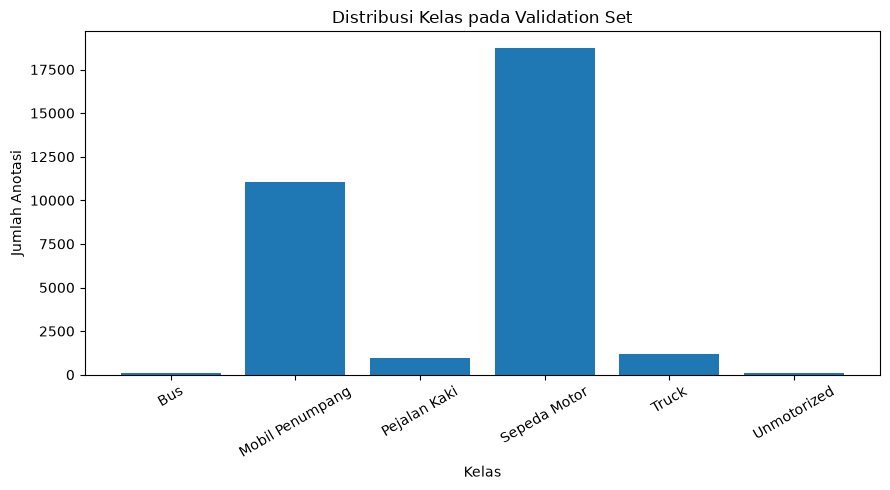

In [13]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.bar(
    class_df["Class"],
    class_df["Annotations"],
)

ax.set_title(
    "Distribusi Kelas pada Validation Set"
)

ax.set_xlabel(
    "Kelas"
)

ax.set_ylabel(
    "Jumlah Anotasi"
)

ax.tick_params(
    axis="x",
    rotation=30,
)

plt.tight_layout()
plt.show()

In [15]:
import torch

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Evaluation device:", DEVICE)

metrics = model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640,
    batch=8,
    device=DEVICE,
    plots=True,
    project=str(EVAL_DIR),
    name="overall_validation",
    exist_ok=True,
    verbose=True,
)

Evaluation device: cpu
Ultralytics 8.4.155  Python-3.11.14 torch-2.14.0+cpu CPU (12th Gen Intel Core i5-12450HX)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients
WARNING val: Slow image access detected (ping: 0.10.0 ms, read: 31.78.5 MB/s, size: 235.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Local D\Galeri Belajar\Skripsi\data\audited_v2\valid\labels... 1790 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1790/1790 864.6it/s 2.1s0.0s
val: New cache created: C:\Local D\Galeri Belajar\Skripsi\data\audited_v2\valid\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 224/224 2.2it/s 1:410.4sss
                   all       1790      32076      0.767      0.672      0.744      0.527
                   Bus         81         97      0.763      0.729      0.788      0.668
       Mobil 

In [16]:
# ============================================================
# STEP 4A — TABEL 3.5
# KINERJA DETEKSI KESELURUHAN BASELINE SEED 42
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Extract metrics dari evaluasi sebelumnya
# ------------------------------------------------------------

precision = float(metrics.box.mp)
recall = float(metrics.box.mr)
map50 = float(metrics.box.map50)
map5095 = float(metrics.box.map)

f1 = (
    2 * precision * recall
    / (precision + recall)
    if (precision + recall) > 0
    else 0.0
)


# ------------------------------------------------------------
# TABEL 3.5
# ------------------------------------------------------------

table_35 = pd.DataFrame([
    {
        "Model": "YOLO26n FPN-PAN",
        "Seed": 42,
        "mAP50-95": map5095,
        "mAP50": map50,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
    }
])


print("Tabel 3.5 — Kinerja Deteksi Secara Keseluruhan")

display(
    table_35.style
    .format({
        "mAP50-95": "{:.4f}",
        "mAP50": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# SAVE TABLE
# ------------------------------------------------------------

table_35.to_csv(
    EVAL_DIR / "tabel_3_5_baseline_seed42.csv",
    index=False,
)

Tabel 3.5 — Kinerja Deteksi Secara Keseluruhan


Model,Seed,mAP50-95,mAP50,Precision,Recall,F1-score
YOLO26n FPN-PAN,42,0.5268,0.7438,0.7669,0.6724,0.7165


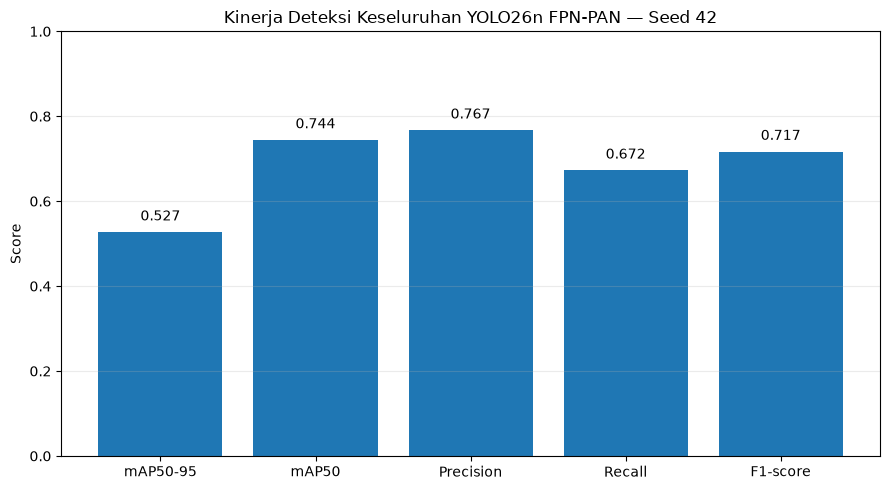

In [17]:
# ============================================================
# GRAFIK — KINERJA DETEKSI KESELURUHAN
# ============================================================

overall_plot = pd.DataFrame({
    "Metric": [
        "mAP50-95",
        "mAP50",
        "Precision",
        "Recall",
        "F1-score",
    ],
    "Score": [
        map5095,
        map50,
        precision,
        recall,
        f1,
    ],
})


fig, ax = plt.subplots(
    figsize=(9, 5)
)

bars = ax.bar(
    overall_plot["Metric"],
    overall_plot["Score"],
)

ax.set_title(
    "Kinerja Deteksi Keseluruhan YOLO26n FPN-PAN — Seed 42"
)

ax.set_ylabel(
    "Score"
)

ax.set_ylim(
    0,
    1.0,
)

ax.grid(
    axis="y",
    alpha=0.25,
)


# Nilai di atas setiap bar
for bar, value in zip(
    bars,
    overall_plot["Score"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )


plt.tight_layout()

plt.savefig(
    EVAL_DIR / "overall_performance_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [20]:
# ============================================================
# STEP 4B — TABEL 3.6
# AP50-95 PER KELAS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CLASS_NAMES = [
    "Bus",
    "Mobil Penumpang",
    "Pejalan Kaki",
    "Sepeda Motor",
    "Truck",
    "Unmotorized",
]

# ------------------------------------------------------------
# Ambil AP50-95 per kelas dari metrics hasil model.val()
# ------------------------------------------------------------

ap_values = np.asarray(
    metrics.box.ap,
    dtype=float,
)

class_indices = np.asarray(
    metrics.box.ap_class_index,
    dtype=int,
)

ap_per_class = np.full(
    len(CLASS_NAMES),
    np.nan,
)

for class_id, ap in zip(
    class_indices,
    ap_values,
):
    ap_per_class[class_id] = ap


# ------------------------------------------------------------
# TABEL 3.6 — FORMAT RESMI SKRIPSI
# ------------------------------------------------------------

table_36 = pd.DataFrame([
    {
        "Model": "YOLO26n FPN-PAN",
        "Bus": ap_per_class[0],
        "Mobil Penumpang": ap_per_class[1],
        "Pejalan Kaki": ap_per_class[2],
        "Sepeda Motor": ap_per_class[3],
        "Truck": ap_per_class[4],
        "Unmotorized": ap_per_class[5],
    }
])

print("Tabel 3.6 — Evaluasi Berdasarkan Kelas Objek")

display(
    table_36.style
    .format({
        "Bus": "{:.4f}",
        "Mobil Penumpang": "{:.4f}",
        "Pejalan Kaki": "{:.4f}",
        "Sepeda Motor": "{:.4f}",
        "Truck": "{:.4f}",
        "Unmotorized": "{:.4f}",
    })
    .hide(axis="index")
)

table_36.to_csv(
    EVAL_DIR / "tabel_3_6_ap_per_kelas_seed42.csv",
    index=False,
)

Tabel 3.6 — Evaluasi Berdasarkan Kelas Objek


Model,Bus,Mobil Penumpang,Pejalan Kaki,Sepeda Motor,Truck,Unmotorized
YOLO26n FPN-PAN,0.6684,0.7202,0.3643,0.4072,0.6249,0.3761


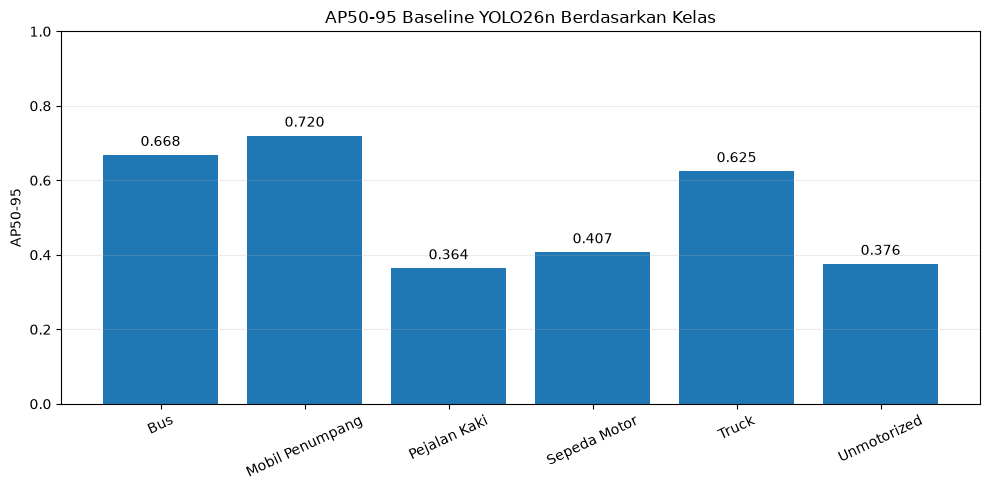

In [21]:
# ============================================================
# GRAFIK AP50-95 PER KELAS
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5)
)

bars = ax.bar(
    CLASS_NAMES,
    ap_per_class,
)

ax.set_title(
    "AP50-95 Baseline YOLO26n Berdasarkan Kelas"
)

ax.set_ylabel(
    "AP50-95"
)

ax.set_ylim(
    0,
    1.0,
)

ax.tick_params(
    axis="x",
    rotation=25,
)

ax.grid(
    axis="y",
    alpha=0.25,
)

for bar, value in zip(
    bars,
    ap_per_class,
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()

plt.savefig(
    EVAL_DIR / "ap_per_class_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [22]:
%pip install -q pycocotools

Note: you may need to restart the kernel to use updated packages.


c:\Local D\Galeri Belajar\Skripsi\.venv\Scripts\python.exe: No module named pip


In [23]:
# ============================================================
# STEP 4C — TABEL 3.7
# AP-S / AP-M / AP-L @ 640x640
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


IMGSZ = 640

IMAGE_EXTS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
}


# ============================================================
# 1. BUILD COCO GROUND TRUTH PADA CANVAS 640x640
# ============================================================

val_images = sorted(
    p for p in VAL_IMAGES.iterdir()
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTS
)

image_id_map = {
    str(path.resolve()): idx
    for idx, path in enumerate(
        val_images,
        start=1,
    )
}


coco_dataset = {
    "info": {},
    "licenses": [],
    "images": [],
    "annotations": [],
    "categories": [
        {
            "id": i + 1,
            "name": name,
        }
        for i, name in enumerate(CLASS_NAMES)
    ],
}


annotation_id = 1


for image_path in val_images:

    image_id = image_id_map[
        str(image_path.resolve())
    ]

    with Image.open(image_path) as im:
        orig_w, orig_h = im.size


    # Letterbox scale menuju 640x640
    scale = min(
        IMGSZ / orig_w,
        IMGSZ / orig_h,
    )

    resized_w = orig_w * scale
    resized_h = orig_h * scale

    pad_x = (
        IMGSZ - resized_w
    ) / 2

    pad_y = (
        IMGSZ - resized_h
    ) / 2


    coco_dataset["images"].append({
        "id": image_id,
        "file_name": image_path.name,
        "width": IMGSZ,
        "height": IMGSZ,
    })


    label_path = (
        VAL_LABELS
        / f"{image_path.stem}.txt"
    )

    text = label_path.read_text(
        encoding="utf-8"
    ).strip()


    if not text:
        continue


    for line in text.splitlines():

        cls, xc, yc, w, h = map(
            float,
            line.split(),
        )

        cls = int(cls)


        # YOLO normalized -> original pixel coordinates
        x1 = (
            xc - w / 2
        ) * orig_w

        y1 = (
            yc - h / 2
        ) * orig_h

        x2 = (
            xc + w / 2
        ) * orig_w

        y2 = (
            yc + h / 2
        ) * orig_h


        # Original -> letterboxed 640x640 coordinates
        x1 = x1 * scale + pad_x
        y1 = y1 * scale + pad_y
        x2 = x2 * scale + pad_x
        y2 = y2 * scale + pad_y


        bw = max(
            0.0,
            x2 - x1,
        )

        bh = max(
            0.0,
            y2 - y1,
        )


        coco_dataset[
            "annotations"
        ].append({
            "id": annotation_id,
            "image_id": image_id,
            "category_id": cls + 1,
            "bbox": [
                x1,
                y1,
                bw,
                bh,
            ],
            "area": bw * bh,
            "iscrowd": 0,
        })

        annotation_id += 1


print(
    "Ground truth annotations:",
    len(
        coco_dataset["annotations"]
    ),
)

assert (
    len(coco_dataset["annotations"])
    == 32076
)

Ground truth annotations: 32076


In [26]:
# ============================================================
# STEP 4C.2 — MEMORY-SAFE VALIDATION INFERENCE
# ============================================================

import gc
import torch
from pathlib import Path

# Bersihkan sisa object dari attempt sebelumnya
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


prediction_results = []

print("Source :", VAL_IMAGES)
print("Device : cpu")
print("Mode   : streaming / memory-safe")


# PENTING:
# source = FOLDER, bukan list 1790 image.
results_stream = model.predict(
    source=str(VAL_IMAGES),
    imgsz=640,
    conf=0.001,
    max_det=300,
    device="cpu",
    batch=1,
    stream=True,
    verbose=False,
)


processed = 0


for result in results_stream:

    image_path = Path(
        result.path
    ).resolve()

    image_key = str(image_path)

    if image_key not in image_id_map:
        raise KeyError(
            f"Image tidak ditemukan pada map:\n{image_path}"
        )

    image_id = image_id_map[
        image_key
    ]


    # --------------------------------------------------------
    # Ukuran citra asli
    # --------------------------------------------------------

    orig_h, orig_w = result.orig_shape


    # Letterbox scale menuju 640 × 640
    scale = min(
        640 / orig_w,
        640 / orig_h,
    )

    resized_w = orig_w * scale
    resized_h = orig_h * scale

    pad_x = (
        640 - resized_w
    ) / 2

    pad_y = (
        640 - resized_h
    ) / 2


    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    if result.boxes is not None:

        boxes = (
            result.boxes.xyxy
            .cpu()
            .numpy()
        )

        confs = (
            result.boxes.conf
            .cpu()
            .numpy()
        )

        classes = (
            result.boxes.cls
            .cpu()
            .numpy()
            .astype(int)
        )


        for box, conf, cls in zip(
            boxes,
            confs,
            classes,
        ):

            x1, y1, x2, y2 = box


            # Koordinat original image
            # -> evaluation canvas 640×640
            x1 = x1 * scale + pad_x
            y1 = y1 * scale + pad_y
            x2 = x2 * scale + pad_x
            y2 = y2 * scale + pad_y


            bw = max(
                0.0,
                x2 - x1,
            )

            bh = max(
                0.0,
                y2 - y1,
            )


            prediction_results.append({
                "image_id": image_id,
                "category_id": int(cls) + 1,

                "bbox": [
                    float(x1),
                    float(y1),
                    float(bw),
                    float(bh),
                ],

                "score": float(conf),
            })


    processed += 1


    # Progress
    if (
        processed % 100 == 0
        or processed == len(val_images)
    ):
        print(
            f"{processed}/{len(val_images)} images | "
            f"{len(prediction_results)} predictions"
        )


    # Buang object result secepat mungkin
    del result


gc.collect()


print("\n" + "=" * 60)

print(
    "Images processed :",
    processed,
)

print(
    "Predictions      :",
    len(prediction_results),
)

print(
    "Inference cache  : READY"
)

print("=" * 60)


assert processed == 1790

Source : C:\Local D\Galeri Belajar\Skripsi\data\audited_v2\valid\images
Device : cpu
Mode   : streaming / memory-safe
100/1790 images | 10644 predictions
200/1790 images | 31715 predictions
300/1790 images | 35174 predictions
400/1790 images | 40365 predictions
500/1790 images | 53422 predictions
600/1790 images | 61327 predictions
700/1790 images | 64498 predictions
800/1790 images | 67772 predictions
900/1790 images | 71631 predictions
1000/1790 images | 75027 predictions
1100/1790 images | 81344 predictions
1200/1790 images | 89565 predictions
1300/1790 images | 108838 predictions
1400/1790 images | 129380 predictions
1500/1790 images | 153505 predictions
1600/1790 images | 170577 predictions
1700/1790 images | 198354 predictions
1790/1790 images | 221932 predictions

Images processed : 1790
Predictions      : 221932
Inference cache  : READY


In [27]:
# ============================================================
# 3. COCO SCALE EVALUATION
# ============================================================

coco_gt = COCO()

coco_gt.dataset = coco_dataset
coco_gt.createIndex()


coco_dt = coco_gt.loadRes(
    prediction_results
)


coco_eval = COCOeval(
    coco_gt,
    coco_dt,
    "bbox",
)

# Konsisten dengan max_det prediction
coco_eval.params.maxDets = [
    1,
    10,
    300,
]


coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()


# COCO stats:
# index 3 = AP small
# index 4 = AP medium
# index 5 = AP large

ap_small = float(
    coco_eval.stats[3]
)

ap_medium = float(
    coco_eval.stats[4]
)

ap_large = float(
    coco_eval.stats[5]
)


# ============================================================
# TABEL 3.7 — FORMAT SKRIPSI
# ============================================================

table_37 = pd.DataFrame([
    {
        "Model": "YOLO26n FPN-PAN",
        "AP-S": ap_small,
        "AP-M": ap_medium,
        "AP-L": ap_large,
    }
])


print(
    "\nTabel 3.7 — Evaluasi Berdasarkan Skala Objek"
)

display(
    table_37.style
    .format({
        "AP-S": "{:.4f}",
        "AP-M": "{:.4f}",
        "AP-L": "{:.4f}",
    })
    .hide(axis="index")
)


table_37.to_csv(
    EVAL_DIR
    / "tabel_3_7_ap_skala_seed42.csv",
    index=False,
)

creating index...
index created!
Loading and preparing results...
DONE (t=0.11s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=29.13s).
Accumulating evaluation results...
DONE (t=1.37s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=300 ] = 0.720
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=300 ] = 0.561
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=300 ] = 0.321
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=300 ] = 0.564
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=300 ] = 0.446
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.302
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.553
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=300 ] = 0.616
 Average Recall     (AR) @[ IoU=0

Model,AP-S,AP-M,AP-L
YOLO26n FPN-PAN,0.3210,0.5640,0.4464


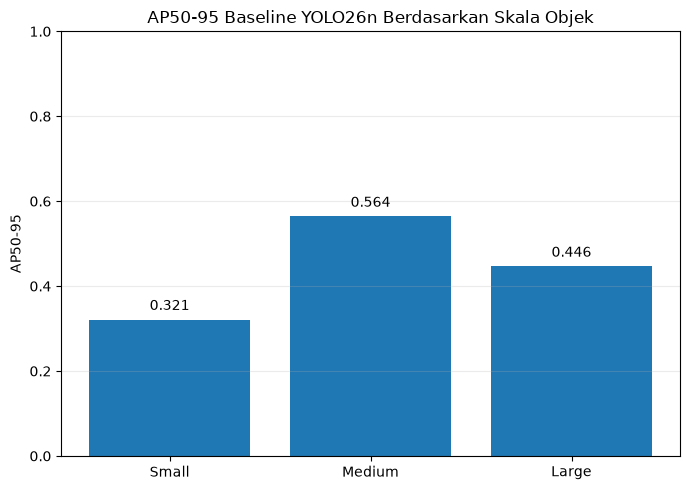

In [29]:
# ============================================================
# GRAFIK — AP BERDASARKAN SKALA
# ============================================================

scale_names = [
    "Small",
    "Medium",
    "Large",
]

scale_ap = [
    ap_small,
    ap_medium,
    ap_large,
]


fig, ax = plt.subplots(
    figsize=(7, 5)
)

bars = ax.bar(
    scale_names,
    scale_ap,
)


ax.set_title(
    "AP50-95 Baseline YOLO26n Berdasarkan Skala Objek"
)

ax.set_ylabel(
    "AP50-95"
)

ax.set_ylim(
    0,
    1.0,
)

ax.grid(
    axis="y",
    alpha=0.25,
)


for bar, value in zip(
    bars,
    scale_ap,
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,

        value + 0.015,

        f"{value:.3f}",

        ha="center",
        va="bottom",
    )


plt.tight_layout()

plt.savefig(
    EVAL_DIR
    / "ap_by_scale_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [31]:
# ============================================================
# CHECK THOP + RETRY GFLOPS
# ============================================================

import sys
import subprocess

try:
    import thop
    print("THOP tersedia")
    print("THOP version:", getattr(thop, "__version__", "unknown"))

except ImportError:
    print("THOP belum tersedia -> installing ultralytics-thop...")

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-U",
        "ultralytics-thop",
    ])

    import thop
    print("THOP berhasil diinstall")


# ------------------------------------------------------------
# Coba profiler Ultralytics langsung
# ------------------------------------------------------------

from ultralytics.utils.torch_utils import get_flops

gflops_test = get_flops(
    model.model,
    imgsz=640,
)

print("\nGFLOPs @ 640x640:", gflops_test)

THOP tersedia
THOP version: 0.1.1

GFLOPs @ 640x640: 0.0


YOLO26n summary: 260 layers, 2,506,140 parameters, 0 gradients
Model Complexity — Baseline YOLO26n FPN-PAN


Model,Parameters (M),GFLOPs,Model Size (MB)
YOLO26n FPN-PAN,2.506,0.000,5.12


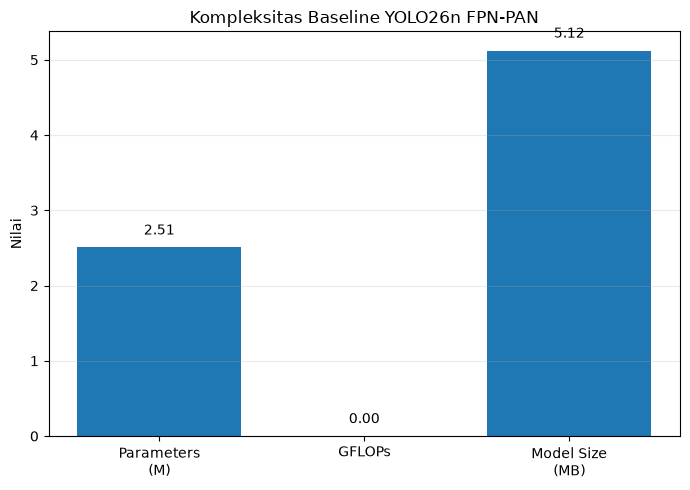


MODEL COMPLEXITY SUMMARY
Parameters : 2.506 M
GFLOPs     : 0.000
Model Size : 5.12 MB
Layers     : 260


In [32]:
# ============================================================
# STEP 4C — MODEL COMPLEXITY
# BASELINE YOLO26n FPN-PAN — SEED 42
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. PROFILE MODEL @ 640x640
# ------------------------------------------------------------

layers, params, gradients, gflops = model.info(
    detailed=False,
    verbose=True,
    imgsz=640,
)


# ------------------------------------------------------------
# 2. CHECKPOINT SIZE
# ------------------------------------------------------------

# Pakai BEST_PT jika sebelumnya sudah didefinisikan.
# Fallback ke checkpoint yang tersimpan pada object model.
try:
    checkpoint_path = Path(BEST_PT)
except NameError:
    checkpoint_path = Path(model.ckpt_path)

assert checkpoint_path.exists(), (
    f"Checkpoint tidak ditemukan: {checkpoint_path}"
)

model_size_mb = (
    checkpoint_path.stat().st_size
    / (1024 ** 2)
)


# ------------------------------------------------------------
# 3. TABEL MODEL COMPLEXITY
# ------------------------------------------------------------

complexity_df = pd.DataFrame([
    {
        "Model": "YOLO26n FPN-PAN",
        "Parameters (M)": params / 1e6,
        "GFLOPs": gflops,
        "Model Size (MB)": model_size_mb,
    }
])


print(
    "Model Complexity — Baseline YOLO26n FPN-PAN"
)

display(
    complexity_df.style
    .format({
        "Parameters (M)": "{:.3f}",
        "GFLOPs": "{:.3f}",
        "Model Size (MB)": "{:.2f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 4. SAVE TABLE
# ------------------------------------------------------------

complexity_df.to_csv(
    EVAL_DIR / "model_complexity_seed42.csv",
    index=False,
)


# ------------------------------------------------------------
# 5. GRAFIK
# ------------------------------------------------------------

metric_names = [
    "Parameters\n(M)",
    "GFLOPs",
    "Model Size\n(MB)",
]

metric_values = [
    params / 1e6,
    gflops,
    model_size_mb,
]


fig, ax = plt.subplots(
    figsize=(7, 5)
)

bars = ax.bar(
    metric_names,
    metric_values,
)

ax.set_title(
    "Kompleksitas Baseline YOLO26n FPN-PAN"
)

ax.set_ylabel(
    "Nilai"
)

ax.grid(
    axis="y",
    alpha=0.25,
)


for bar, value in zip(
    bars,
    metric_values,
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(metric_values) * 0.025,
        f"{value:.2f}",
        ha="center",
        va="bottom",
    )


plt.tight_layout()

plt.savefig(
    EVAL_DIR / "model_complexity_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("MODEL COMPLEXITY SUMMARY")
print("=" * 55)

print(
    f"Parameters : {params / 1e6:.3f} M"
)

print(
    f"GFLOPs     : {gflops:.3f}"
)

print(
    f"Model Size : {model_size_mb:.2f} MB"
)

print(
    f"Layers     : {layers}"
)

print("=" * 55)

In [33]:
# ============================================================
# DEBUG GFLOPS — TAMPILKAN ERROR ASLI THOP
# ============================================================

import torch
import thop
import traceback

net = model.model
net.eval()

device = next(net.parameters()).device
dtype = next(net.parameters()).dtype

dummy = torch.zeros(
    1, 3, 640, 640,
    device=device,
    dtype=dtype,
)

print("Model device :", device)
print("Input shape  :", tuple(dummy.shape))
print("THOP version :", getattr(thop, "__version__", "unknown"))

try:
    macs, params_thop = thop.profile(
        net,
        inputs=(dummy,),
        verbose=False,
    )

    # Ultralytics convention:
    # 1 MAC = 2 FLOPs
    gflops = macs * 2 / 1e9

    print("\nPROFILE SUCCESS")
    print(f"MACs       : {macs / 1e9:.4f} GMACs")
    print(f"GFLOPs     : {gflops:.4f}")
    print(f"Parameters : {params_thop / 1e6:.4f} M")

except Exception as e:
    print("\nPROFILE FAILED")
    print(type(e).__name__, ":", e)
    traceback.print_exc()

Model device : cpu
Input shape  : (1, 3, 640, 640)
THOP version : 0.1.1

PROFILE SUCCESS
MACs       : 2.8913 GMACs
GFLOPs     : 5.7825
Parameters : 2.5061 M


In [36]:
# ============================================================
# STEP 4C — MODEL COMPLEXITY
# BASELINE YOLO26n FPN-PAN — SEED 42
# ============================================================

from pathlib import Path

import pandas as pd
import torch
import thop


# ------------------------------------------------------------
# 1. MODEL SETUP
# ------------------------------------------------------------

net = model.model
net.eval()

device = next(net.parameters()).device
dtype = next(net.parameters()).dtype


# ------------------------------------------------------------
# 2. TOTAL PARAMETERS
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in net.parameters()
)

params_m = total_params / 1e6


# ------------------------------------------------------------
# 3. GMACs & GFLOPs @ 640 x 640
# ------------------------------------------------------------

dummy = torch.zeros(
    1,
    3,
    640,
    640,
    device=device,
    dtype=dtype,
)

macs, _ = thop.profile(
    net,
    inputs=(dummy,),
    verbose=False,
)

gmacs = macs / 1e9

# Konvensi yang kita gunakan:
# 1 MAC = 2 FLOPs
gflops = (macs * 2) / 1e9


# ------------------------------------------------------------
# 4. CHECKPOINT SIZE
# ------------------------------------------------------------

try:
    checkpoint_path = Path(BEST_PT)

except NameError:
    checkpoint_path = Path(
        model.ckpt_path
    )

assert checkpoint_path.exists(), (
    f"Checkpoint tidak ditemukan: {checkpoint_path}"
)

model_size_mb = (
    checkpoint_path.stat().st_size
    / (1024 ** 2)
)


# ------------------------------------------------------------
# 5. TABLE
# ------------------------------------------------------------

complexity_df = pd.DataFrame([
    {
        "Model": "YOLO26n FPN-PAN",
        "Parameters (M)": params_m,
        "GMACs": gmacs,
        "GFLOPs": gflops,
        "Model Size (MB)": model_size_mb,
    }
])


print(
    "Model Complexity — Baseline YOLO26n FPN-PAN"
)

display(
    complexity_df.style
    .format({
        "Parameters (M)": "{:.4f}",
        "GMACs": "{:.4f}",
        "GFLOPs": "{:.4f}",
        "Model Size (MB)": "{:.2f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 6. SAVE
# ------------------------------------------------------------

complexity_df.to_csv(
    EVAL_DIR / "model_complexity_seed42.csv",
    index=False,
)


# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("MODEL COMPLEXITY SUMMARY")
print("=" * 50)

print(f"Parameters : {params_m:.4f} M")
print(f"GMACs      : {gmacs:.4f}")
print(f"GFLOPs     : {gflops:.4f}")
print(f"Model Size : {model_size_mb:.2f} MB")

print("=" * 50)

Model Complexity — Baseline YOLO26n FPN-PAN


Model,Parameters (M),GMACs,GFLOPs,Model Size (MB)
YOLO26n FPN-PAN,2.5061,2.8913,5.7825,5.12



MODEL COMPLEXITY SUMMARY
Parameters : 2.5061 M
GMACs      : 2.8913
GFLOPs     : 5.7825
Model Size : 5.12 MB


creating index...
index created!
Loading and preparing results...
DONE (t=0.08s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=52.09s).
Accumulating evaluation results...
DONE (t=4.42s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=300 ] = 0.720
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=300 ] = 0.561
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=300 ] = 0.321
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=300 ] = 0.564
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=300 ] = 0.446
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.302
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.553
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=300 ] = 0.616
 Average Recall     (AR) @[ IoU=0

Model,AP-S,AP-M,AP-L
YOLO26n FPN-PAN,0.3210,0.5640,0.4464


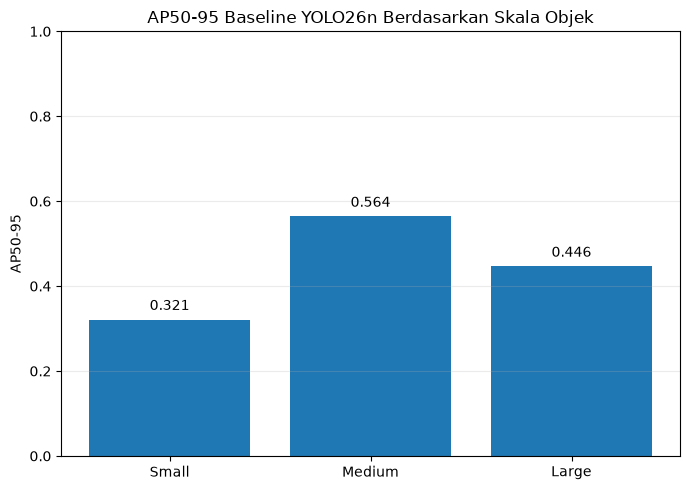


SCALE PERFORMANCE SUMMARY
AP-S : 0.3210
AP-M : 0.5640
AP-L : 0.4464


In [37]:
# ============================================================
# STEP 4D — TABEL 3.7
# EVALUASI BERDASARKAN SKALA OBJEK
# ============================================================

import json
import pandas as pd
import matplotlib.pyplot as plt

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


# ------------------------------------------------------------
# 1. LOAD PREDICTION CACHE JIKA VARIABLE SUDAH HILANG
# ------------------------------------------------------------

if "prediction_results" not in globals():
    PRED_CACHE = (
        EVAL_DIR
        / "validation_predictions_seed42.json"
    )

    with open(
        PRED_CACHE,
        "r",
        encoding="utf-8",
    ) as f:
        prediction_results = json.load(f)

    print(
        "Prediction cache loaded:",
        len(prediction_results)
    )


assert "coco_dataset" in globals(), (
    "coco_dataset belum tersedia. "
    "Jalankan cell pembuatan COCO ground truth sebelumnya."
)


# ------------------------------------------------------------
# 2. BUILD COCO EVALUATOR
# ------------------------------------------------------------

coco_gt = COCO()
coco_gt.dataset = coco_dataset
coco_gt.createIndex()

coco_dt = coco_gt.loadRes(
    prediction_results
)

coco_eval = COCOeval(
    coco_gt,
    coco_dt,
    "bbox",
)

# Dense traffic → konsisten dengan max_det inference
coco_eval.params.maxDets = [
    1,
    10,
    300,
]


# ------------------------------------------------------------
# 3. EVALUATE
# ------------------------------------------------------------

coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()


# ------------------------------------------------------------
# 4. EXTRACT AP-S / AP-M / AP-L
# ------------------------------------------------------------

ap_small = float(
    coco_eval.stats[3]
)

ap_medium = float(
    coco_eval.stats[4]
)

ap_large = float(
    coco_eval.stats[5]
)


# ------------------------------------------------------------
# 5. TABEL 3.7
# ------------------------------------------------------------

table_37 = pd.DataFrame([
    {
        "Model": "YOLO26n FPN-PAN",
        "AP-S": ap_small,
        "AP-M": ap_medium,
        "AP-L": ap_large,
    }
])


print(
    "\nTabel 3.7 — Evaluasi Berdasarkan Skala Objek"
)

display(
    table_37.style
    .format({
        "AP-S": "{:.4f}",
        "AP-M": "{:.4f}",
        "AP-L": "{:.4f}",
    })
    .hide(axis="index")
)


table_37.to_csv(
    EVAL_DIR
    / "tabel_3_7_ap_skala_seed42.csv",
    index=False,
)


# ------------------------------------------------------------
# 6. GRAFIK
# ------------------------------------------------------------

scale_names = [
    "Small",
    "Medium",
    "Large",
]

scale_values = [
    ap_small,
    ap_medium,
    ap_large,
]


fig, ax = plt.subplots(
    figsize=(7, 5)
)

bars = ax.bar(
    scale_names,
    scale_values,
)

ax.set_title(
    "AP50-95 Baseline YOLO26n Berdasarkan Skala Objek"
)

ax.set_ylabel(
    "AP50-95"
)

ax.set_ylim(
    0,
    1.0,
)

ax.grid(
    axis="y",
    alpha=0.25,
)


for bar, value in zip(
    bars,
    scale_values,
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
        va="bottom",
    )


plt.tight_layout()

plt.savefig(
    EVAL_DIR
    / "ap_by_scale_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 45)
print("SCALE PERFORMANCE SUMMARY")
print("=" * 45)

print(f"AP-S : {ap_small:.4f}")
print(f"AP-M : {ap_medium:.4f}")
print(f"AP-L : {ap_large:.4f}")

print("=" * 45)

Validation output:
C:\Local D\Galeri Belajar\Skripsi\reports\baseline_seed42_evaluation\overall_validation


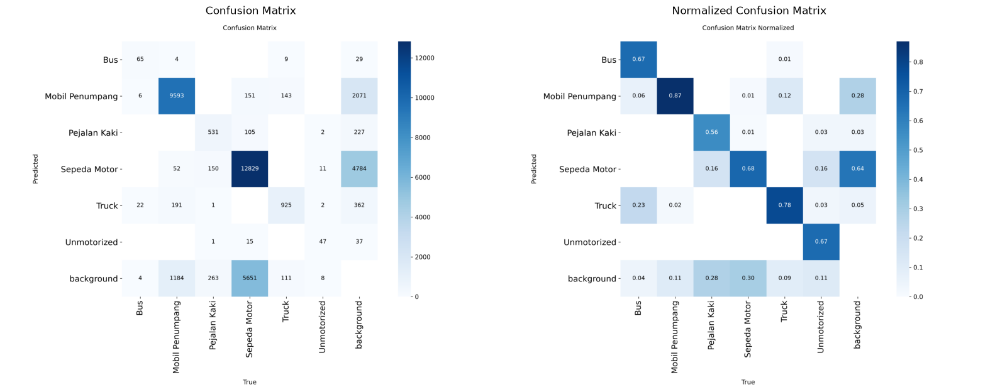

In [38]:
# ============================================================
# STEP 4E.1 — CONFUSION MATRIX
# ============================================================

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Folder hasil model.val() sebelumnya
try:
    VAL_RUN_DIR = Path(metrics.save_dir)
except Exception:
    VAL_RUN_DIR = (
        EVAL_DIR
        / "overall_validation"
    )

print("Validation output:")
print(VAL_RUN_DIR)


# ------------------------------------------------------------
# Cari confusion matrix
# ------------------------------------------------------------

cm_path = (
    VAL_RUN_DIR
    / "confusion_matrix.png"
)

cm_norm_path = (
    VAL_RUN_DIR
    / "confusion_matrix_normalized.png"
)


assert cm_path.exists(), (
    f"File tidak ditemukan: {cm_path}"
)

assert cm_norm_path.exists(), (
    f"File tidak ditemukan: {cm_norm_path}"
)


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7),
)

axes[0].imshow(
    Image.open(cm_path)
)

axes[0].set_title(
    "Confusion Matrix"
)

axes[0].axis("off")


axes[1].imshow(
    Image.open(cm_norm_path)
)

axes[1].set_title(
    "Normalized Confusion Matrix"
)

axes[1].axis("off")


plt.tight_layout()
plt.show()

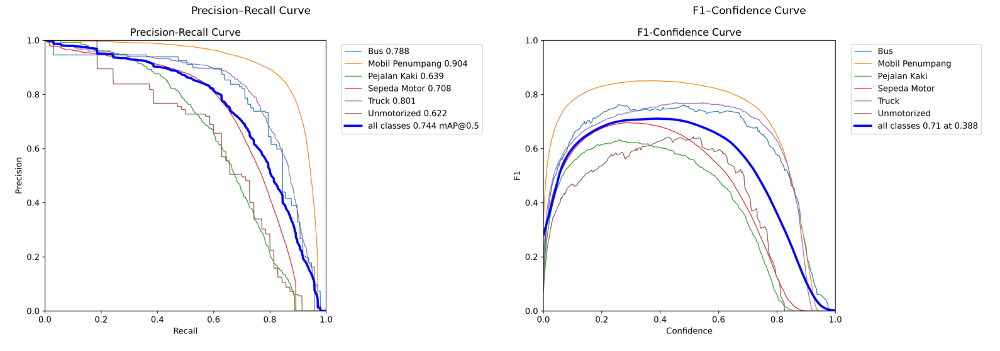

In [39]:
# ============================================================
# STEP 4E.2 — PR CURVE + F1 CURVE
# ============================================================

pr_path = (
    VAL_RUN_DIR
    / "BoxPR_curve.png"
)

f1_path = (
    VAL_RUN_DIR
    / "BoxF1_curve.png"
)


assert pr_path.exists(), (
    f"File tidak ditemukan: {pr_path}"
)

assert f1_path.exists(), (
    f"File tidak ditemukan: {f1_path}"
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7),
)


axes[0].imshow(
    Image.open(pr_path)
)

axes[0].set_title(
    "Precision–Recall Curve"
)

axes[0].axis("off")


axes[1].imshow(
    Image.open(f1_path)
)

axes[1].set_title(
    "F1–Confidence Curve"
)

axes[1].axis("off")


plt.tight_layout()
plt.show()

In [40]:
# ============================================================
# STEP 4F — 10 GROUND TRUTH vs PREDICTION
# ============================================================

import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# 1. REPRODUCIBLE SAMPLE
# ------------------------------------------------------------

random.seed(42)

sample_images = random.sample(
    val_images,
    10,
)

CONF_VIS = 0.388   # best aggregate F1 threshold dari validation


# ------------------------------------------------------------
# 2. HELPER — DRAW GROUND TRUTH
# ------------------------------------------------------------

def draw_ground_truth(image_path):

    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]

    label_path = (
        VAL_LABELS
        / f"{image_path.stem}.txt"
    )

    if not label_path.exists():
        return img

    text = label_path.read_text(
        encoding="utf-8"
    ).strip()

    if not text:
        return img

    for line in text.splitlines():

        cls, xc, yc, bw, bh = map(
            float,
            line.split()
        )

        cls = int(cls)

        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        cv2.rectangle(
            img,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2,
        )

        cv2.putText(
            img,
            CLASS_NAMES[cls],
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            1,
            cv2.LINE_AA,
        )

    return img

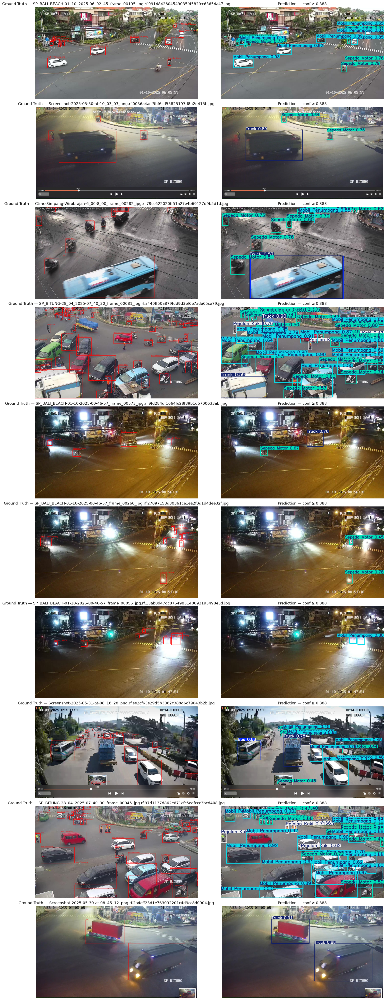

In [41]:
# ============================================================
# 3. PREDICTION + 10 x 2 VISUALIZATION
# ============================================================

pred_results = model.predict(
    source=[str(p) for p in sample_images],
    imgsz=640,
    conf=CONF_VIS,
    device="cpu",
    verbose=False,
)


fig, axes = plt.subplots(
    10,
    2,
    figsize=(18, 45),
)


for i, (image_path, result) in enumerate(
    zip(sample_images, pred_results)
):

    # -------------------------
    # Ground Truth
    # -------------------------

    gt_img = draw_ground_truth(
        image_path
    )

    axes[i, 0].imshow(
        gt_img
    )

    axes[i, 0].set_title(
        f"Ground Truth — {image_path.name}"
    )

    axes[i, 0].axis("off")


    # -------------------------
    # Prediction
    # -------------------------

    pred_img = result.plot(
        conf=True,
        labels=True,
    )

    pred_img = cv2.cvtColor(
        pred_img,
        cv2.COLOR_BGR2RGB,
    )

    axes[i, 1].imshow(
        pred_img
    )

    axes[i, 1].set_title(
        f"Prediction — conf ≥ {CONF_VIS:.3f}"
    )

    axes[i, 1].axis("off")


plt.tight_layout()

plt.savefig(
    EVAL_DIR
    / "gt_vs_prediction_10_images_seed42.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

In [42]:
# ============================================================
# FAILURE DIAGNOSTIC 1 — LOCALIZATION QUALITY
# mAP50-95 vs AP50 vs AP75
# ============================================================

import json
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


# ------------------------------------------------------------
# 1. LOAD CACHE JIKA VARIABLE SUDAH HILANG
# ------------------------------------------------------------

if "prediction_results" not in globals():

    PRED_CACHE = (
        EVAL_DIR
        / "validation_predictions_seed42.json"
    )

    with open(
        PRED_CACHE,
        "r",
        encoding="utf-8",
    ) as f:
        prediction_results = json.load(f)


assert "coco_dataset" in globals(), (
    "coco_dataset belum tersedia."
)


# ------------------------------------------------------------
# 2. BUILD COCO EVALUATOR
# ------------------------------------------------------------

coco_gt = COCO()
coco_gt.dataset = coco_dataset
coco_gt.createIndex()

coco_dt = coco_gt.loadRes(
    prediction_results
)

coco_eval = COCOeval(
    coco_gt,
    coco_dt,
    "bbox",
)

coco_eval.params.maxDets = [
    1,
    10,
    300,
]


# ------------------------------------------------------------
# 3. EVALUATE
# ------------------------------------------------------------

coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()


# ------------------------------------------------------------
# 4. EXTRACT METRICS
# ------------------------------------------------------------

coco_map5095 = float(
    coco_eval.stats[0]
)

coco_ap50 = float(
    coco_eval.stats[1]
)

coco_ap75 = float(
    coco_eval.stats[2]
)

ap50_ap75_gap = (
    coco_ap50
    - coco_ap75
)


# ------------------------------------------------------------
# 5. DIAGNOSTIC TABLE
# ------------------------------------------------------------

localization_df = pd.DataFrame([
    {
        "Model": "YOLO26n FPN-PAN",
        "mAP50-95": coco_map5095,
        "AP50": coco_ap50,
        "AP75": coco_ap75,
        "AP50-AP75 Gap": ap50_ap75_gap,
    }
])


print(
    "\nLocalization Diagnostic — Baseline Seed 42"
)

display(
    localization_df.style
    .format({
        "mAP50-95": "{:.4f}",
        "AP50": "{:.4f}",
        "AP75": "{:.4f}",
        "AP50-AP75 Gap": "{:.4f}",
    })
    .hide(axis="index")
)


localization_df.to_csv(
    EVAL_DIR
    / "localization_diagnostic_seed42.csv",
    index=False,
)


print("\n" + "=" * 50)
print("LOCALIZATION SUMMARY")
print("=" * 50)

print(
    f"mAP50-95 : {coco_map5095:.4f}"
)

print(
    f"AP50      : {coco_ap50:.4f}"
)

print(
    f"AP75      : {coco_ap75:.4f}"
)

print(
    f"Gap 50→75 : {ap50_ap75_gap:.4f}"
)

print("=" * 50)

creating index...
index created!
Loading and preparing results...
DONE (t=0.10s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=25.50s).
Accumulating evaluation results...
DONE (t=1.46s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=300 ] = 0.720
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=300 ] = 0.561
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=300 ] = 0.321
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=300 ] = 0.564
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=300 ] = 0.446
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.302
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.553
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=300 ] = 0.616
 Average Recall     (AR) @[ IoU=0

Model,mAP50-95,AP50,AP75,AP50-AP75 Gap
YOLO26n FPN-PAN,-1.0000,0.7203,0.5607,0.1596



LOCALIZATION SUMMARY
mAP50-95 : -1.0000
AP50      : 0.7203
AP75      : 0.5607
Gap 50→75 : 0.1596


### Temuan Awal — Localization Quality

Evaluasi pada validation set menunjukkan **AP50 sebesar 0.7203** dan **AP75 sebesar 0.5607**, sehingga terdapat penurunan sebesar **0.1596 poin** ketika ambang IoU dinaikkan dari 0.50 menjadi 0.75.

Penurunan tersebut menunjukkan bahwa sebagian deteksi yang dianggap benar pada kriteria IoU yang lebih longgar tidak lagi memenuhi kriteria ketika ketepatan lokasi bounding box diperketat. Dengan demikian, terdapat **indikasi awal adanya penurunan kualitas lokalisasi pada IoU tinggi**.

Namun, hasil ini **belum cukup untuk menyimpulkan bahwa localization merupakan failure mode utama baseline**. Analisis lanjutan masih diperlukan melalui distribusi IoU pada matched prediction, jumlah false negative, serta evaluasi berdasarkan skala objek. Hal tersebut diperlukan untuk membedakan apakah penurunan performa terutama disebabkan oleh bounding box yang kurang presisi atau oleh objek yang sama sekali gagal dideteksi.

> **Catatan evaluasi:** nilai `mAP50-95 = -1.0000` pada output COCOeval tidak merepresentasikan performa model. Nilai tersebut muncul karena evaluasi menggunakan `maxDets = [1, 10, 300]`, sedangkan statistik mAP50-95 standar pada fungsi `summarize()` mengacu pada konfigurasi `maxDets=100`. Oleh karena itu, nilai mAP50-95 baseline yang digunakan tetap berasal dari evaluasi Ultralytics sebelumnya, yaitu sekitar **0.527**.

In [43]:
# ============================================================
# FAILURE DIAGNOSTIC 2 — OBJECT SCALE
# AP-S / AP-M / AP-L + GT DISTRIBUTION
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. EXTRACT SCALE AP
#
# COCOeval:
# stats[3] = AP Small
# stats[4] = AP Medium
# stats[5] = AP Large
# ------------------------------------------------------------

ap_small = float(coco_eval.stats[3])
ap_medium = float(coco_eval.stats[4])
ap_large = float(coco_eval.stats[5])


# ------------------------------------------------------------
# 2. COUNT GT OBJECTS BY SCALE
#
# Threshold COCO pada evaluation canvas 640x640:
# Small  : area < 32^2
# Medium : 32^2 <= area < 96^2
# Large  : area >= 96^2
# ------------------------------------------------------------

SMALL_MAX = 32 ** 2
MEDIUM_MAX = 96 ** 2

scale_counts = {
    "Small": 0,
    "Medium": 0,
    "Large": 0,
}


for ann in coco_dataset["annotations"]:

    area = ann["area"]

    if area < SMALL_MAX:
        scale_counts["Small"] += 1

    elif area < MEDIUM_MAX:
        scale_counts["Medium"] += 1

    else:
        scale_counts["Large"] += 1


total_gt = sum(scale_counts.values())


# ------------------------------------------------------------
# 3. DIAGNOSTIC TABLE
# ------------------------------------------------------------

scale_df = pd.DataFrame([
    {
        "Scale": "Small",
        "GT Objects": scale_counts["Small"],
        "GT (%)": scale_counts["Small"] / total_gt * 100,
        "AP50-95": ap_small,
    },
    {
        "Scale": "Medium",
        "GT Objects": scale_counts["Medium"],
        "GT (%)": scale_counts["Medium"] / total_gt * 100,
        "AP50-95": ap_medium,
    },
    {
        "Scale": "Large",
        "GT Objects": scale_counts["Large"],
        "GT (%)": scale_counts["Large"] / total_gt * 100,
        "AP50-95": ap_large,
    },
])


print(
    "Object Scale Diagnostic — Baseline YOLO26n Seed 42"
)

display(
    scale_df.style
    .format({
        "GT (%)": "{:.2f}%",
        "AP50-95": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 4. SAVE
# ------------------------------------------------------------

scale_df.to_csv(
    EVAL_DIR / "scale_diagnostic_seed42.csv",
    index=False,
)


# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("OBJECT SCALE SUMMARY")
print("=" * 55)

print(
    f"Small  : {scale_counts['Small']:5d} objects "
    f"({scale_counts['Small']/total_gt*100:.2f}%) "
    f"| AP-S = {ap_small:.4f}"
)

print(
    f"Medium : {scale_counts['Medium']:5d} objects "
    f"({scale_counts['Medium']/total_gt*100:.2f}%) "
    f"| AP-M = {ap_medium:.4f}"
)

print(
    f"Large  : {scale_counts['Large']:5d} objects "
    f"({scale_counts['Large']/total_gt*100:.2f}%) "
    f"| AP-L = {ap_large:.4f}"
)

print("-" * 55)

print(
    "Total GT:",
    total_gt
)

print("=" * 55)

Object Scale Diagnostic — Baseline YOLO26n Seed 42


Scale,GT Objects,GT (%),AP50-95
Small,25393,79.17%,0.3210
Medium,6097,19.01%,0.5640
Large,586,1.83%,0.4464



OBJECT SCALE SUMMARY
Small  : 25393 objects (79.17%) | AP-S = 0.3210
Medium :  6097 objects (19.01%) | AP-M = 0.5640
Large  :   586 objects (1.83%) | AP-L = 0.4464
-------------------------------------------------------
Total GT: 32076


### Temuan — Kinerja Berdasarkan Skala Objek

Distribusi objek pada validation set menunjukkan bahwa dataset sangat didominasi oleh objek berukuran kecil. Dari total **32.076 objek**, sebanyak **25.393 objek (79,17%)** termasuk kategori *small*, **6.097 objek (19,01%)** termasuk kategori *medium*, dan hanya **586 objek (1,83%)** termasuk kategori *large*.

Baseline YOLO26n menghasilkan **AP-S sebesar 0,3210**, **AP-M sebesar 0,5640**, dan **AP-L sebesar 0,4464**. Nilai AP-S merupakan yang terendah, dengan selisih sekitar **0,243 poin terhadap AP-M**.

Hasil ini memberikan **indikasi kuat bahwa deteksi objek berukuran kecil merupakan salah satu failure mode utama baseline YOLO26n pada IndoTraffic**. Temuan tersebut menjadi semakin relevan karena objek kecil bukan merupakan kasus minor, tetapi justru mencakup hampir empat perlima seluruh anotasi pada validation set.

Namun, nilai AP-L yang lebih rendah daripada AP-M perlu ditafsirkan secara hati-hati karena objek besar hanya mencakup **1,83%** dari seluruh ground truth. Oleh karena itu, performa kategori large memiliki jumlah sampel yang jauh lebih sedikit dibandingkan small dan medium.

Temuan skala ini belum cukup untuk menentukan intervensi arsitektur secara langsung. Analisis selanjutnya perlu mengidentifikasi **kelas apa yang paling banyak berkontribusi terhadap rendahnya AP-S**, sehingga dapat diketahui apakah masalah small-object terjadi secara umum atau terkonsentrasi pada kelas tertentu seperti pejalan kaki atau sepeda motor.

In [44]:
# ============================================================
# FAILURE DIAGNOSTIC 3 — SCALE × CLASS DISTRIBUTION
# ============================================================

import pandas as pd


SMALL_MAX = 32 ** 2
MEDIUM_MAX = 96 ** 2


rows = []

for ann in coco_dataset["annotations"]:

    class_id = ann["category_id"] - 1
    area = ann["area"]

    if area < SMALL_MAX:
        scale = "Small"

    elif area < MEDIUM_MAX:
        scale = "Medium"

    else:
        scale = "Large"


    rows.append({
        "Class": CLASS_NAMES[class_id],
        "Scale": scale,
    })


scale_class_df = pd.DataFrame(rows)


# ------------------------------------------------------------
# COUNT TABLE
# ------------------------------------------------------------

scale_class_count = pd.crosstab(
    scale_class_df["Class"],
    scale_class_df["Scale"],
)


# Pastikan urutan kolom
scale_class_count = scale_class_count.reindex(
    columns=[
        "Small",
        "Medium",
        "Large",
    ],
    fill_value=0,
)


scale_class_count["Total"] = (
    scale_class_count.sum(axis=1)
)


# ------------------------------------------------------------
# PERCENTAGE WITHIN EACH CLASS
# ------------------------------------------------------------

scale_class_pct = (
    scale_class_count[
        ["Small", "Medium", "Large"]
    ]
    .div(
        scale_class_count["Total"],
        axis=0,
    )
    * 100
)


print(
    "Distribusi Skala per Kelas — Validation Set"
)

display(
    scale_class_count
)

print(
    "\nPersentase Skala di Dalam Masing-masing Kelas"
)

display(
    scale_class_pct.style.format(
        "{:.2f}%"
    )
)

Distribusi Skala per Kelas — Validation Set


Scale,Small,Medium,Large,Total
Class,,,,
Bus,6,57,34,97
Mobil Penumpang,6928,3880,216,11024
Pejalan Kaki,915,30,1,946
Sepeda Motor,17317,1432,2,18751
Truck,210,645,333,1188
Unmotorized,17,53,0,70



Persentase Skala di Dalam Masing-masing Kelas


Scale,Small,Medium,Large
Class,,,
Bus,6.19%,58.76%,35.05%
Mobil Penumpang,62.84%,35.20%,1.96%
Pejalan Kaki,96.72%,3.17%,0.11%
Sepeda Motor,92.35%,7.64%,0.01%
Truck,17.68%,54.29%,28.03%
Unmotorized,24.29%,75.71%,0.00%


### Temuan — Distribusi Skala pada Setiap Kelas

Analisis distribusi skala menunjukkan bahwa dominasi objek kecil tidak terjadi secara merata pada seluruh kelas. **Pejalan Kaki (96,72%)** dan **Sepeda Motor (92,35%)** hampir seluruhnya berada pada kategori *small*. Kedua kelas tersebut juga sebelumnya menunjukkan AP50-95 yang relatif rendah, masing-masing sekitar **0,364** dan **0,407**. Hal ini memperkuat indikasi bahwa skala objek berkontribusi terhadap kesulitan deteksi pada kedua kelas tersebut.

Namun, ukuran objek kecil tidak dapat menjelaskan seluruh kelemahan baseline. **Mobil Penumpang** juga memiliki proporsi objek kecil yang tinggi, yaitu **62,84%**, tetapi menghasilkan AP50-95 tertinggi di antara seluruh kelas, sekitar **0,720**. Sebaliknya, kelas **Unmotorized** didominasi objek berukuran medium (**75,71%**) tetapi tetap menghasilkan AP50-95 yang relatif rendah, sekitar **0,376**.

Dengan demikian, hasil ini menunjukkan bahwa **small-object detection merupakan salah satu faktor penting, tetapi bukan satu-satunya faktor yang menentukan kegagalan baseline YOLO26n**. Terdapat indikasi adanya interaksi antara **skala objek dan karakteristik kelas**.

Analisis berikutnya perlu mengukur AP untuk setiap kombinasi kelas dan skala (*scale × class*). Analisis tersebut diperlukan untuk menentukan apakah, misalnya, rendahnya performa Pejalan Kaki dan Sepeda Motor memang terkonsentrasi pada objek kecil, serta apakah objek kecil dari kelas Mobil Penumpang tetap dapat dideteksi dengan baik.

In [45]:
# ============================================================
# FAILURE DIAGNOSTIC 4 — AP SCALE × CLASS
# ============================================================

import numpy as np
import pandas as pd


# COCO precision shape:
# [IoU thresholds, Recall thresholds, Categories, Areas, MaxDets]
precision = coco_eval.eval["precision"]

# Area indices COCO:
# 0 = all
# 1 = small
# 2 = medium
# 3 = large

AREA_INDEX = {
    "Small": 1,
    "Medium": 2,
    "Large": 3,
}

# maxDets terakhir = 300
MAXDET_INDEX = len(
    coco_eval.params.maxDets
) - 1


rows = []


for class_idx, class_name in enumerate(CLASS_NAMES):

    row = {
        "Class": class_name,
    }

    for scale_name, area_idx in AREA_INDEX.items():

        # Semua IoU thresholds
        # Semua recall thresholds
        values = precision[
            :,
            :,
            class_idx,
            area_idx,
            MAXDET_INDEX,
        ]

        # COCO menggunakan -1 untuk kondisi tanpa evaluasi valid
        valid = values[
            values > -1
        ]

        ap = (
            float(valid.mean())
            if len(valid) > 0
            else np.nan
        )

        row[
            f"AP-{scale_name[0]}"
        ] = ap

    rows.append(row)


scale_class_ap_df = pd.DataFrame(
    rows
)


print(
    "AP50-95 Berdasarkan Kelas × Skala"
)

display(
    scale_class_ap_df.style
    .format({
        "AP-S": "{:.4f}",
        "AP-M": "{:.4f}",
        "AP-L": "{:.4f}",
    })
    .hide(axis="index")
)


scale_class_ap_df.to_csv(
    EVAL_DIR
    / "ap_scale_by_class_seed42.csv",
    index=False,
)

AP50-95 Berdasarkan Kelas × Skala


Class,AP-S,AP-M,AP-L
Bus,0.2062,0.6066,0.7053
Mobil Penumpang,0.6398,0.8185,0.8198
Pejalan Kaki,0.3528,0.2556,0.0000
Sepeda Motor,0.3902,0.6004,0.0000
Truck,0.2800,0.6329,0.7067
Unmotorized,0.0573,0.4701,nan


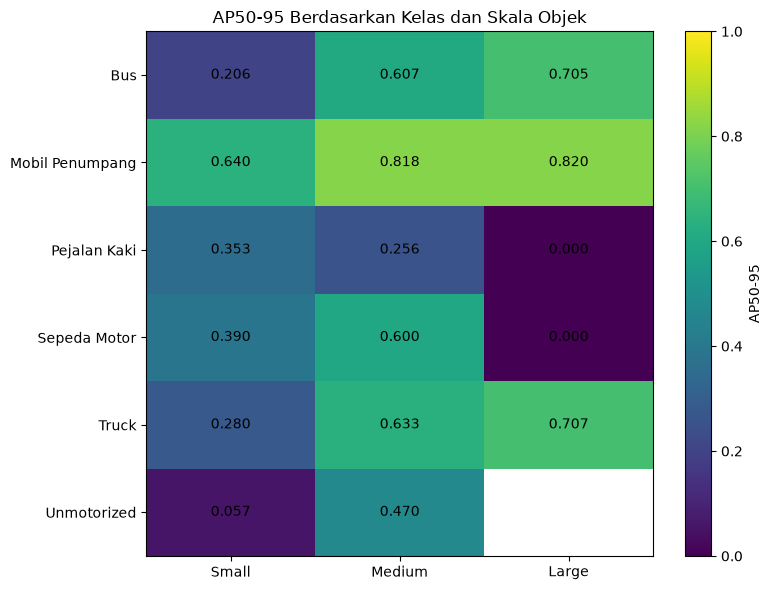

In [46]:
# ============================================================
# HEATMAP — AP SCALE × CLASS
# ============================================================

import matplotlib.pyplot as plt


heatmap_data = (
    scale_class_ap_df[
        ["AP-S", "AP-M", "AP-L"]
    ]
    .to_numpy()
)


fig, ax = plt.subplots(
    figsize=(8, 6)
)

im = ax.imshow(
    heatmap_data,
    aspect="auto",
    vmin=0,
    vmax=1,
)


ax.set_xticks(
    range(3)
)

ax.set_xticklabels([
    "Small",
    "Medium",
    "Large",
])


ax.set_yticks(
    range(len(CLASS_NAMES))
)

ax.set_yticklabels(
    CLASS_NAMES
)


for i in range(
    len(CLASS_NAMES)
):
    for j in range(3):

        value = heatmap_data[i, j]

        if not np.isnan(value):

            ax.text(
                j,
                i,
                f"{value:.3f}",
                ha="center",
                va="center",
            )


ax.set_title(
    "AP50-95 Berdasarkan Kelas dan Skala Objek"
)

fig.colorbar(
    im,
    ax=ax,
    label="AP50-95",
)

plt.tight_layout()

plt.savefig(
    EVAL_DIR
    / "ap_scale_by_class_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

### Temuan — Interaksi Kelas dan Skala Objek

Evaluasi berdasarkan kombinasi kelas dan skala menunjukkan bahwa rendahnya kinerja pada objek kecil tidak terjadi secara seragam pada seluruh kelas.

Pada kategori *small*, **Mobil Penumpang** masih menghasilkan AP yang relatif tinggi sebesar **0,6398**, sedangkan **Sepeda Motor** hanya mencapai **0,3902**, **Pejalan Kaki** sebesar **0,3528**, **Truck** sebesar **0,2800**, dan **Unmotorized** sebesar **0,0573**. Dengan demikian, ukuran objek kecil saja tidak cukup untuk menjelaskan kegagalan baseline karena model tetap mampu mendeteksi objek kecil dari kelas tertentu dengan baik.

Temuan ini terutama penting untuk kelas **Pejalan Kaki** dan **Sepeda Motor**, karena masing-masing kelas didominasi oleh objek kecil sebesar **96,72%** dan **92,35%**. Kinerja keduanya pada kategori small tetap relatif rendah, sehingga terdapat indikasi bahwa baseline mengalami kesulitan pada **objek kecil dengan karakteristik kelas tertentu**, bukan pada seluruh small object secara umum.

Sebaliknya, Mobil Penumpang juga memiliki proporsi objek kecil yang besar (**62,84%**), tetapi menghasilkan AP-S sebesar **0,6398**. Hal ini menunjukkan bahwa keterbatasan baseline kemungkinan melibatkan interaksi antara **ukuran objek, karakteristik visual kelas, dan kondisi pengamatan**, bukan hanya mekanisme representasi multiskala secara umum.

Nilai AP-L untuk Pejalan Kaki dan Sepeda Motor perlu ditafsirkan secara hati-hati karena jumlah objek besar pada kedua kelas tersebut sangat sedikit. Demikian pula, AP-L pada Unmotorized tidak tersedia karena tidak terdapat ground-truth kategori large yang memadai untuk evaluasi.

Secara keseluruhan, hasil ini mempersempit failure hypothesis dari sekadar *small-object detection problem* menjadi **class-dependent small-object detection problem**. Analisis error berikutnya diperlukan untuk menentukan apakah rendahnya AP pada kombinasi tersebut terutama berasal dari missed detection (false negative), kesalahan klasifikasi, atau bounding-box localization.

In [47]:
# ============================================================
# FAILURE DIAGNOSTIC 5
# TP / FN / RECALL PER CLASS × SCALE
# conf = 0.388 | IoU = 0.50
# ============================================================

from collections import defaultdict
import numpy as np
import pandas as pd


CONF_THRESHOLD = 0.388
IOU_THRESHOLD = 0.50

SMALL_MAX = 32 ** 2
MEDIUM_MAX = 96 ** 2


# ------------------------------------------------------------
# 1. HELPER
# ------------------------------------------------------------

def bbox_iou_xywh(box1, box2):

    x1, y1, w1, h1 = box1
    x2, y2, w2, h2 = box2

    xa = max(x1, x2)
    ya = max(y1, y2)

    xb = min(x1 + w1, x2 + w2)
    yb = min(y1 + h1, y2 + h2)

    inter_w = max(0.0, xb - xa)
    inter_h = max(0.0, yb - ya)

    intersection = inter_w * inter_h

    union = (
        w1 * h1
        + w2 * h2
        - intersection
    )

    if union <= 0:
        return 0.0

    return intersection / union


def get_scale(area):

    if area < SMALL_MAX:
        return "Small"

    elif area < MEDIUM_MAX:
        return "Medium"

    else:
        return "Large"


# ------------------------------------------------------------
# 2. GROUP GT & PREDICTION PER IMAGE
# ------------------------------------------------------------

gt_by_image = defaultdict(list)

for ann in coco_dataset["annotations"]:

    gt_by_image[
        ann["image_id"]
    ].append({
        "category_id": ann["category_id"],
        "bbox": ann["bbox"],
        "area": ann["area"],
    })


pred_by_image = defaultdict(list)

for pred in prediction_results:

    if pred["score"] < CONF_THRESHOLD:
        continue

    pred_by_image[
        pred["image_id"]
    ].append({
        "category_id": pred["category_id"],
        "bbox": pred["bbox"],
        "score": pred["score"],
    })


# ------------------------------------------------------------
# 3. MATCHING
# ------------------------------------------------------------

records = []


for image in coco_dataset["images"]:

    image_id = image["id"]

    gt_list = gt_by_image.get(
        image_id,
        [],
    )

    pred_list = pred_by_image.get(
        image_id,
        [],
    )


    # confidence tinggi diproses lebih dulu
    pred_list = sorted(
        pred_list,
        key=lambda x: x["score"],
        reverse=True,
    )


    matched_gt = set()


    for pred in pred_list:

        best_iou = 0.0
        best_gt_idx = None


        for gt_idx, gt in enumerate(gt_list):

            if gt_idx in matched_gt:
                continue

            # Same-class matching
            if (
                pred["category_id"]
                != gt["category_id"]
            ):
                continue


            iou = bbox_iou_xywh(
                pred["bbox"],
                gt["bbox"],
            )


            if iou > best_iou:

                best_iou = iou
                best_gt_idx = gt_idx


        if (
            best_gt_idx is not None
            and best_iou >= IOU_THRESHOLD
        ):
            matched_gt.add(
                best_gt_idx
            )


    # --------------------------------------------------------
    # RECORD SETIAP GT:
    # matched = TP
    # unmatched = FN
    # --------------------------------------------------------

    for gt_idx, gt in enumerate(gt_list):

        class_idx = (
            gt["category_id"] - 1
        )

        scale = get_scale(
            gt["area"]
        )

        matched = (
            gt_idx in matched_gt
        )


        records.append({
            "Class": CLASS_NAMES[class_idx],
            "Scale": scale,
            "TP": int(matched),
            "FN": int(not matched),
        })


# ------------------------------------------------------------
# 4. AGGREGATE CLASS × SCALE
# ------------------------------------------------------------

gt_detection_df = pd.DataFrame(
    records
)


recall_scale_class = (
    gt_detection_df
    .groupby(
        ["Class", "Scale"],
        observed=False,
    )
    .agg(
        GT=("TP", "size"),
        TP=("TP", "sum"),
        FN=("FN", "sum"),
    )
    .reset_index()
)


recall_scale_class["Recall"] = (
    recall_scale_class["TP"]
    / recall_scale_class["GT"]
)


# ------------------------------------------------------------
# 5. SORT
# ------------------------------------------------------------

class_order = {
    name: i
    for i, name in enumerate(CLASS_NAMES)
}

scale_order = {
    "Small": 0,
    "Medium": 1,
    "Large": 2,
}


recall_scale_class["_class_order"] = (
    recall_scale_class["Class"]
    .map(class_order)
)

recall_scale_class["_scale_order"] = (
    recall_scale_class["Scale"]
    .map(scale_order)
)


recall_scale_class = (
    recall_scale_class
    .sort_values(
        [
            "_class_order",
            "_scale_order",
        ]
    )
    .drop(
        columns=[
            "_class_order",
            "_scale_order",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. DISPLAY
# ------------------------------------------------------------

print(
    "TP / FN / Recall per Class × Scale"
)

print(
    f"Confidence >= {CONF_THRESHOLD}"
)

print(
    f"IoU >= {IOU_THRESHOLD}"
)


display(
    recall_scale_class.style
    .format({
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 7. SAVE
# ------------------------------------------------------------

recall_scale_class.to_csv(
    EVAL_DIR
    / "recall_class_scale_seed42.csv",
    index=False,
)

TP / FN / Recall per Class × Scale
Confidence >= 0.388
IoU >= 0.5


Class,Scale,GT,TP,FN,Recall
Bus,Small,6,1,5,0.1667
Bus,Medium,57,42,15,0.7368
Bus,Large,34,29,5,0.8529
Mobil Penumpang,Small,6928,5414,1514,0.7815
Mobil Penumpang,Medium,3880,3553,327,0.9157
Mobil Penumpang,Large,216,205,11,0.9491
Pejalan Kaki,Small,915,455,460,0.4973
Pejalan Kaki,Medium,30,13,17,0.4333
Pejalan Kaki,Large,1,0,1,0.0000
Sepeda Motor,Small,17317,9708,7609,0.5606


### Temuan — Missed Detection Berdasarkan Kelas dan Skala

Analisis pada operating point `confidence = 0,388` dan `IoU = 0,50` menunjukkan bahwa penurunan kinerja pada objek kecil terutama berkaitan dengan **missed detection**.

Pada kategori *small*, terdapat **25.393 ground-truth object**, tetapi hanya sekitar **15.659 objek yang berhasil dipasangkan dengan prediksi benar**, sedangkan sekitar **9.734 objek menjadi false negative**. Hal ini menghasilkan recall agregat objek kecil sekitar **61,7%**. Sebagai perbandingan, recall agregat kategori *medium* berada sekitar **88,3%**, sedangkan kategori *large* sekitar **91,0%**, meskipun jumlah objek large jauh lebih sedikit.

Kelas **Sepeda Motor-small** menjadi kontributor terbesar terhadap false negative. Dari **17.317 objek kecil**, hanya **9.708** yang berhasil dideteksi, sedangkan **7.609 objek terlewat**, dengan recall hanya **0,5606**. Sebaliknya, Sepeda Motor berukuran medium menghasilkan recall **0,8380**. Perbedaan ini menunjukkan adanya penurunan kemampuan deteksi yang kuat ketika objek Sepeda Motor berada pada skala kecil.

Pola serupa juga terlihat pada kelas **Truck**, dengan recall small hanya **0,3714**, sementara medium mencapai **0,8279** dan large **0,8979**. Kelas **Mobil Penumpang** juga mengalami penurunan pada small object, tetapi masih mempertahankan recall relatif tinggi sebesar **0,7815**, dibandingkan 0,9157 pada medium dan 0,9491 pada large.

Untuk **Pejalan Kaki**, recall small hanya **0,4973**, tetapi recall medium juga rendah yaitu **0,4333**. Hal ini menunjukkan bahwa kelemahan Pejalan Kaki kemungkinan tidak hanya disebabkan oleh skala objek, melainkan juga oleh karakteristik kelas atau kondisi visual lainnya.

Secara keseluruhan, hasil ini memperkuat indikasi bahwa salah satu failure mode utama baseline YOLO26n adalah **missed detection pada objek kecil**, terutama pada kelas Sepeda Motor. Namun, karena proses matching menggunakan kelas yang sama, false negative pada analisis ini masih dapat mencakup beberapa penyebab berbeda, seperti prediksi ber-confidence rendah, kesalahan klasifikasi, atau kesalahan lokalisasi. Oleh karena itu, tahap selanjutnya perlu memisahkan penyebab false negative tersebut.

In [48]:
# ============================================================
# FAILURE DIAGNOSTIC 6
# FALSE NEGATIVE DECOMPOSITION
#
# Operating point:
# confidence >= 0.388
# TP IoU >= 0.50
#
# FN dibagi menjadi:
# 1. match_conflict
# 2. misclassification
# 3. low_confidence
# 4. localization
# 5. no_candidate
# ============================================================

from collections import defaultdict
import numpy as np
import pandas as pd


CONF_THRESHOLD = 0.388
IOU_TP = 0.50

# Hanya sebagai proxy kandidat localization.
# Bukan threshold evaluasi resmi.
IOU_LOCALIZATION_MIN = 0.10


# ------------------------------------------------------------
# 1. IoU helper
# ------------------------------------------------------------

def bbox_iou_xywh(box1, box2):

    x1, y1, w1, h1 = box1
    x2, y2, w2, h2 = box2

    xa = max(x1, x2)
    ya = max(y1, y2)

    xb = min(x1 + w1, x2 + w2)
    yb = min(y1 + h1, y2 + h2)

    inter_w = max(0.0, xb - xa)
    inter_h = max(0.0, yb - ya)

    intersection = (
        inter_w * inter_h
    )

    union = (
        w1 * h1
        + w2 * h2
        - intersection
    )

    if union <= 0:
        return 0.0

    return intersection / union


# ------------------------------------------------------------
# 2. Scale helper
# ------------------------------------------------------------

SMALL_MAX = 32 ** 2
MEDIUM_MAX = 96 ** 2


def get_scale(area):

    if area < SMALL_MAX:
        return "Small"

    elif area < MEDIUM_MAX:
        return "Medium"

    else:
        return "Large"


# ------------------------------------------------------------
# 3. Group GT / predictions
# ------------------------------------------------------------

gt_by_image = defaultdict(list)

for ann in coco_dataset["annotations"]:

    gt_by_image[
        ann["image_id"]
    ].append({
        "category_id": ann["category_id"],
        "bbox": ann["bbox"],
        "area": ann["area"],
    })


pred_by_image = defaultdict(list)

for pred in prediction_results:

    pred_by_image[
        pred["image_id"]
    ].append({
        "category_id": pred["category_id"],
        "bbox": pred["bbox"],
        "score": pred["score"],
    })


# ------------------------------------------------------------
# 4. Process each image
# ------------------------------------------------------------

records = []


for image in coco_dataset["images"]:

    image_id = image["id"]

    gt_list = gt_by_image.get(
        image_id,
        [],
    )

    all_preds = pred_by_image.get(
        image_id,
        [],
    )


    high_preds = [
        p for p in all_preds
        if p["score"] >= CONF_THRESHOLD
    ]

    high_preds = sorted(
        high_preds,
        key=lambda x: x["score"],
        reverse=True,
    )


    # --------------------------------------------------------
    # Standard same-class greedy matching
    # --------------------------------------------------------

    matched_gt = set()


    for pred in high_preds:

        best_iou = 0.0
        best_gt_idx = None


        for gt_idx, gt in enumerate(
            gt_list
        ):

            if gt_idx in matched_gt:
                continue

            if (
                pred["category_id"]
                != gt["category_id"]
            ):
                continue


            iou = bbox_iou_xywh(
                pred["bbox"],
                gt["bbox"],
            )


            if iou > best_iou:

                best_iou = iou
                best_gt_idx = gt_idx


        if (
            best_gt_idx is not None
            and best_iou >= IOU_TP
        ):

            matched_gt.add(
                best_gt_idx
            )


    # --------------------------------------------------------
    # Diagnose every GT
    # --------------------------------------------------------

    for gt_idx, gt in enumerate(
        gt_list
    ):

        class_idx = (
            gt["category_id"] - 1
        )

        scale = get_scale(
            gt["area"]
        )


        # ================================================
        # TP
        # ================================================

        if gt_idx in matched_gt:

            records.append({
                "image_id": image_id,
                "file_name": image["file_name"],

                "Class": CLASS_NAMES[
                    class_idx
                ],

                "Scale": scale,

                "Status": "TP",
                "FN_Reason": None,
            })

            continue


        # ================================================
        # FN DIAGNOSTICS
        # ================================================

        same_high = [
            p for p in high_preds
            if p["category_id"]
            == gt["category_id"]
        ]

        same_low = [
            p for p in all_preds

            if (
                p["category_id"]
                == gt["category_id"]
                and
                p["score"]
                < CONF_THRESHOLD
            )
        ]

        wrong_high = [
            p for p in high_preds

            if (
                p["category_id"]
                != gt["category_id"]
            )
        ]


        # -----------------------------------------------
        # Max IoU helpers
        # -----------------------------------------------

        max_same_high_iou = max(
            [
                bbox_iou_xywh(
                    gt["bbox"],
                    p["bbox"],
                )
                for p in same_high
            ],
            default=0.0,
        )


        max_same_low_iou = max(
            [
                bbox_iou_xywh(
                    gt["bbox"],
                    p["bbox"],
                )
                for p in same_low
            ],
            default=0.0,
        )


        max_wrong_high_iou = max(
            [
                bbox_iou_xywh(
                    gt["bbox"],
                    p["bbox"],
                )
                for p in wrong_high
            ],
            default=0.0,
        )


        # ================================================
        # PRIMARY FN REASON
        # ================================================

        # Ada prediction benar kelas dan IoU >= .5,
        # tetapi sudah "direbut" GT lain.
        if max_same_high_iou >= IOU_TP:

            reason = "match_conflict"


        # Ada prediction high-confidence overlapping,
        # tetapi kelas salah.
        elif max_wrong_high_iou >= IOU_TP:

            reason = "misclassification"


        # Prediction benar sebenarnya ada,
        # tetapi confidence terlalu rendah.
        elif max_same_low_iou >= IOU_TP:

            reason = "low_confidence"


        # Kelas benar + confidence cukup,
        # tetapi bbox belum mencapai IoU .50.
        elif (
            max_same_high_iou
            >= IOU_LOCALIZATION_MIN
        ):

            reason = "localization"


        # Tidak ditemukan kandidat relevan.
        else:

            reason = "no_candidate"


        records.append({

            "image_id": image_id,
            "file_name": image["file_name"],

            "Class": CLASS_NAMES[
                class_idx
            ],

            "Scale": scale,

            "Status": "FN",

            "FN_Reason": reason,

            "max_same_high_iou":
                max_same_high_iou,

            "max_same_low_iou":
                max_same_low_iou,

            "max_wrong_high_iou":
                max_wrong_high_iou,
        })


# ------------------------------------------------------------
# 5. Dataframe
# ------------------------------------------------------------

fn_detail_df = pd.DataFrame(
    records
)

fn_only_df = fn_detail_df[
    fn_detail_df["Status"] == "FN"
].copy()


print(
    "Total FN diagnosed:",
    len(fn_only_df)
)


# ------------------------------------------------------------
# 6. OVERALL FN REASON
# ------------------------------------------------------------

fn_reason_summary = (
    fn_only_df[
        "FN_Reason"
    ]
    .value_counts()
    .rename_axis(
        "FN Reason"
    )
    .reset_index(
        name="Count"
    )
)


fn_reason_summary["Percentage"] = (
    fn_reason_summary["Count"]
    / len(fn_only_df)
    * 100
)


print(
    "\nOverall False Negative Decomposition"
)

display(
    fn_reason_summary.style
    .format({
        "Percentage": "{:.2f}%"
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 7. SMALL OBJECT FN REASON
# ------------------------------------------------------------

small_fn_df = fn_only_df[
    fn_only_df["Scale"] == "Small"
].copy()


small_fn_summary = (
    small_fn_df[
        "FN_Reason"
    ]
    .value_counts()
    .rename_axis(
        "FN Reason"
    )
    .reset_index(
        name="Count"
    )
)


small_fn_summary["Percentage"] = (
    small_fn_summary["Count"]
    / len(small_fn_df)
    * 100
)


print(
    "\nSmall-object False Negative Decomposition"
)

display(
    small_fn_summary.style
    .format({
        "Percentage": "{:.2f}%"
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 8. SMALL FN BY CLASS × REASON
# ------------------------------------------------------------

small_fn_by_class = pd.crosstab(
    small_fn_df["Class"],
    small_fn_df["FN_Reason"],
)


print(
    "\nSmall-object FN by Class"
)

display(
    small_fn_by_class
)


# ------------------------------------------------------------
# 9. SAVE
# ------------------------------------------------------------

fn_detail_df.to_csv(
    EVAL_DIR
    / "fn_diagnostic_per_object_seed42.csv",
    index=False,
)

fn_reason_summary.to_csv(
    EVAL_DIR
    / "fn_reason_summary_seed42.csv",
    index=False,
)

small_fn_by_class.to_csv(
    EVAL_DIR
    / "small_fn_reason_by_class_seed42.csv"
)

Total FN diagnosed: 10500

Overall False Negative Decomposition


FN Reason,Count,Percentage
low_confidence,7163,68.22%
no_candidate,2298,21.89%
misclassification,559,5.32%
localization,478,4.55%
match_conflict,2,0.02%



Small-object False Negative Decomposition


FN Reason,Count,Percentage
low_confidence,6714,68.97%
no_candidate,2199,22.59%
localization,457,4.69%
misclassification,362,3.72%
match_conflict,2,0.02%



Small-object FN by Class


FN_Reason,localization,low_confidence,match_conflict,misclassification,no_candidate
Class,,,,,
Bus,0,0,0,2,3
Mobil Penumpang,33,1090,0,64,327
Pejalan Kaki,2,207,0,87,164
Sepeda Motor,422,5380,2,139,1666
Truck,0,36,0,63,33
Unmotorized,0,1,0,7,6


### Temuan — Dekomposisi Penyebab False Negative

Dari **10.500 false negative** pada operating point `confidence = 0,388` dan `IoU = 0,50`, sebanyak **7.163 kasus (68,22%)** dikategorikan sebagai *low-confidence*. Artinya, pada sebagian besar objek yang dianggap terlewat, model sebenarnya telah menghasilkan prediksi dengan kelas yang benar dan IoU ≥ 0,50, tetapi confidence prediksi berada di bawah threshold operasi.

Sebanyak **2.298 kasus (21,89%)** termasuk kategori *no candidate*, yaitu tidak ditemukan prediksi relevan yang cukup dekat dengan ground truth. Sementara itu, kesalahan klasifikasi hanya menyumbang **5,32%**, kandidat masalah lokalisasi **4,55%**, dan *match conflict* hanya **0,02%**.

Pola yang hampir sama muncul pada objek kecil. Dari **9.734 false negative small-object**, sebanyak **6.714 kasus (68,97%)** disebabkan oleh low-confidence dan **2.199 kasus (22,59%)** tidak memiliki kandidat prediksi yang relevan. Dengan demikian, rendahnya recall small-object tidak semata-mata berarti model gagal membentuk deteksi, tetapi dalam banyak kasus model menghasilkan deteksi yang belum memiliki confidence cukup tinggi.

Failure mode juga berbeda antar kelas. Pada **Sepeda Motor-small**, dari 7.609 false negative, sebanyak **5.380 kasus (~70,7%)** merupakan low-confidence dan **1.666 kasus (~21,9%)** merupakan no-candidate. Hal ini menunjukkan bahwa masalah utama pada small motorcycle lebih banyak berkaitan dengan lemahnya keyakinan model terhadap deteksi yang secara spasial sebenarnya sudah cukup benar.

Pada **Pejalan Kaki-small**, penyebab false negative lebih heterogen: 207 dari 460 kasus merupakan low-confidence, 164 no-candidate, dan 87 misclassification. Oleh karena itu, kelemahan kelas Pejalan Kaki tidak dapat dijelaskan hanya melalui confidence atau skala.

Pada **Truck-small**, pola berbeda kembali terlihat. Dari 132 false negative, sebanyak 63 kasus merupakan misclassification, 36 low-confidence, dan 33 no-candidate. Hal ini mengindikasikan bahwa failure pada small Truck lebih berkaitan dengan pengenalan kelas dibandingkan small motorcycle.

Secara keseluruhan, hasil ini menunjukkan bahwa baseline YOLO26n memiliki **failure mode yang bersifat class-dependent**. Small-object detection merupakan masalah penting, tetapi penyebab kegagalannya berbeda antar kelas. Temuan tersebut dapat menjelaskan mengapa penggantian mekanisme multi-scale feature fusion secara umum belum tentu menghasilkan peningkatan kinerja, karena bottleneck yang ditemukan tidak hanya berkaitan dengan representasi skala tetapi juga confidence dan separabilitas antar kelas.

> Dekomposisi ini merupakan analisis diagnostik pada threshold tertentu dan belum menunjukkan penyebab kausal. Analisis confidence, density, overlap/crowding, dan brightness masih diperlukan untuk mengidentifikasi kondisi yang berasosiasi dengan penurunan confidence atau hilangnya kandidat deteksi.

Low-confidence FN score distribution


,Confidence
count,7163.000000
mean,0.285295
std,0.104964
min,0.001020
10%,0.110495
25%,0.232837
50%,0.326357
75%,0.366113
90%,0.381381
max,0.387965



Median confidence by class


,count,median,mean
Class,,,
Bus,1,0.1243,0.1243
Truck,93,0.1698,0.1735
Pejalan Kaki,209,0.2248,0.2024
Mobil Penumpang,1288,0.2740,0.2417
Unmotorized,7,0.2879,0.2793
Sepeda Motor,5565,0.3386,0.3004


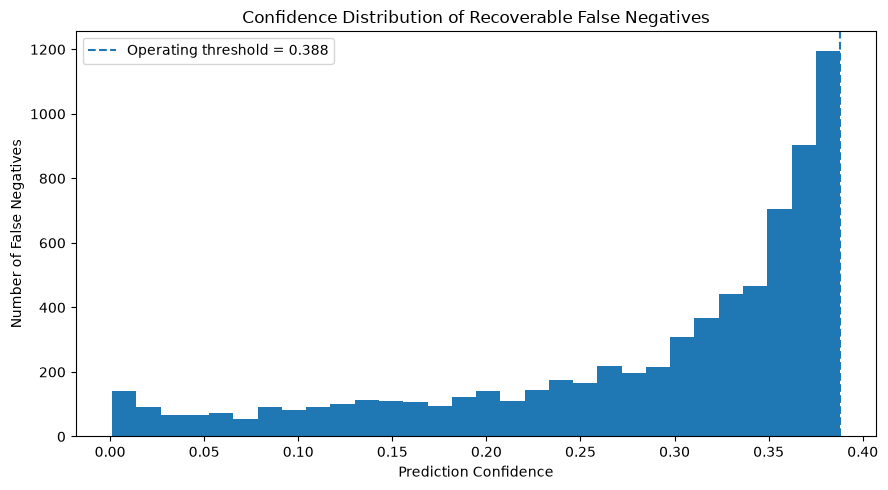

In [49]:
# ============================================================
# FAILURE DIAGNOSTIC 7
# CONFIDENCE DISTRIBUTION OF RECOVERABLE FN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


recoverable_rows = []


for _, fn in fn_only_df.iterrows():

    if fn["FN_Reason"] != "low_confidence":
        continue

    image_id = fn["image_id"]

    # Cari GT yang sesuai lagi dari image tersebut
    # berdasarkan class + scale + status FN.
    # Kita rekonstruksi kandidat melalui prediction cache.

    class_idx = CLASS_NAMES.index(
        fn["Class"]
    )

    category_id = class_idx + 1

    # Ambil semua prediksi kelas yang sama
    preds = [
        p for p in pred_by_image[image_id]
        if (
            p["category_id"] == category_id
            and p["score"] < CONF_THRESHOLD
        )
    ]

    # Karena fn_detail_df menyimpan max_same_low_iou,
    # ambil prediction dengan IoU yang memenuhi >= 0.50
    # dan confidence tertinggi.
    candidate_scores = []

    gt_candidates = gt_by_image[
        image_id
    ]

    # Cari GT dengan class/scale sesuai dan punya
    # low-confidence match yang sama dengan diagnostic record.
    best_score = np.nan

    for gt in gt_candidates:

        if gt["category_id"] != category_id:
            continue

        if get_scale(gt["area"]) != fn["Scale"]:
            continue

        for pred in preds:

            iou = bbox_iou_xywh(
                gt["bbox"],
                pred["bbox"],
            )

            if iou >= IOU_TP:
                candidate_scores.append(
                    pred["score"]
                )

    if candidate_scores:
        best_score = max(
            candidate_scores
        )

    recoverable_rows.append({
        "Class": fn["Class"],
        "Scale": fn["Scale"],
        "Best_Low_Confidence": best_score,
    })


recoverable_conf_df = pd.DataFrame(
    recoverable_rows
).dropna()


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print(
    "Low-confidence FN score distribution"
)

display(
    recoverable_conf_df[
        "Best_Low_Confidence"
    ]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
    .to_frame(
        "Confidence"
    )
)


print(
    "\nMedian confidence by class"
)

class_conf_summary = (
    recoverable_conf_df
    .groupby("Class")
    ["Best_Low_Confidence"]
    .agg([
        "count",
        "median",
        "mean",
    ])
    .sort_values(
        "median"
    )
)

display(
    class_conf_summary.style
    .format({
        "median": "{:.4f}",
        "mean": "{:.4f}",
    })
)


# ------------------------------------------------------------
# HISTOGRAM
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.hist(
    recoverable_conf_df[
        "Best_Low_Confidence"
    ],
    bins=30,
)

ax.axvline(
    CONF_THRESHOLD,
    linestyle="--",
    label=f"Operating threshold = {CONF_THRESHOLD}",
)

ax.set_title(
    "Confidence Distribution of Recoverable False Negatives"
)

ax.set_xlabel(
    "Prediction Confidence"
)

ax.set_ylabel(
    "Number of False Negatives"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    EVAL_DIR
    / "recoverable_fn_confidence_distribution_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

### Temuan — Karakteristik Confidence pada False Negative

Analisis terhadap false negative yang masih memiliki prediksi dengan kelas benar dan IoU ≥ 0,50 menunjukkan adanya perbedaan distribusi confidence antar kelas.

Kelas **Sepeda Motor** menjadi kasus paling dominan, dengan **5.565 false negative low-confidence** dan median confidence sebesar **0,3386**. Nilai tersebut relatif dekat dengan operating threshold `0,388`, sehingga sebagian besar missed detection pada kelas Sepeda Motor bukan berasal dari ketiadaan prediksi, melainkan dari prediksi yang sudah memiliki lokasi dan kelas yang cukup benar tetapi belum mencapai confidence yang diperlukan.

Sebaliknya, kelas **Pejalan Kaki** memiliki median confidence lebih rendah, yaitu **0,2248**, sedangkan **Truck** hanya **0,1698**. Hal ini menunjukkan bahwa false negative pada kedua kelas tersebut cenderung memiliki respons model yang lebih lemah dibandingkan Sepeda Motor.

Mobil Penumpang menghasilkan median confidence **0,2740**, tetapi jumlah kasus low-confidence yang ditemukan jauh lebih kecil dibandingkan Sepeda Motor jika mempertimbangkan jumlah keseluruhan instance. Hal ini konsisten dengan performa Mobil Penumpang yang sebelumnya lebih tinggi pada evaluasi per kelas maupun per skala.

Temuan ini mengindikasikan bahwa rendahnya recall small-object, khususnya pada Sepeda Motor, tidak selalu merepresentasikan kegagalan total dalam menghasilkan kandidat deteksi. Banyak objek telah menghasilkan prediksi yang secara spasial cukup benar, tetapi confidence-nya belum cukup tinggi. Dengan demikian, failure mode baseline melibatkan **kelemahan confidence terhadap objek tertentu selain masalah representasi skala**.

Namun, confidence yang rendah belum dapat dianggap sebagai penyebab utama secara kausal. Confidence dapat dipengaruhi oleh kondisi lain seperti ukuran objek, kepadatan lalu lintas, overlap antarobjek, kualitas visual, maupun pencahayaan. Oleh karena itu, analisis selanjutnya dilakukan terhadap kondisi kepadatan objek, overlap/crowding, dan brightness.

Density thresholds
----------------------------
Low    : GT <= 7
Medium : 7 < GT <= 22
High   : GT > 22

Image distribution


Density,Images
Low,612
Medium,608
High,570



Detection performance by image density


Density,GT,TP,FN,Recall
Low,2831,1620,1211,0.5722
Medium,8454,5661,2793,0.6696
High,20791,14295,6496,0.6876


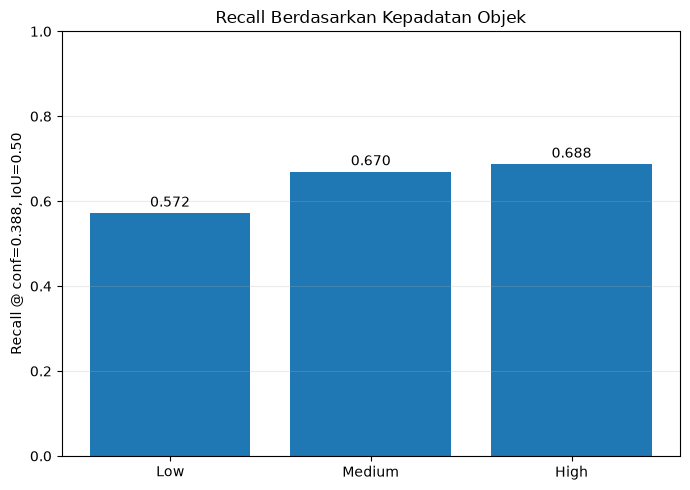

In [50]:
# ============================================================
# FAILURE DIAGNOSTIC 8 — OBJECT DENSITY
# Apakah recall turun pada citra yang semakin padat?
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. HITUNG JUMLAH GT PER IMAGE
# ------------------------------------------------------------

image_gt_counts = {
    img["id"]: len(
        gt_by_image.get(img["id"], [])
    )
    for img in coco_dataset["images"]
}


density_image_df = pd.DataFrame([
    {
        "image_id": image_id,
        "GT_Count": count,
    }
    for image_id, count
    in image_gt_counts.items()
])


# ------------------------------------------------------------
# 2. THRESHOLD BERDASARKAN DISTRIBUSI DATA
# ------------------------------------------------------------

q33 = float(
    density_image_df["GT_Count"]
    .quantile(0.33)
)

q67 = float(
    density_image_df["GT_Count"]
    .quantile(0.67)
)


def density_group(count):

    if count <= q33:
        return "Low"

    elif count <= q67:
        return "Medium"

    else:
        return "High"


density_image_df["Density"] = (
    density_image_df["GT_Count"]
    .apply(density_group)
)


print("Density thresholds")
print("----------------------------")
print(f"Low    : GT <= {q33:.0f}")
print(
    f"Medium : {q33:.0f} < GT <= {q67:.0f}"
)
print(f"High   : GT > {q67:.0f}")


# ------------------------------------------------------------
# 3. DISTRIBUSI IMAGE PER DENSITY
# ------------------------------------------------------------

density_distribution = (
    density_image_df["Density"]
    .value_counts()
    .reindex([
        "Low",
        "Medium",
        "High",
    ])
    .reset_index()
)

density_distribution.columns = [
    "Density",
    "Images",
]


print("\nImage distribution")

display(
    density_distribution.style
    .hide(axis="index")
)


# ------------------------------------------------------------
# 4. JOIN DENGAN HASIL TP / FN PER OBJECT
# ------------------------------------------------------------

density_map = dict(
    zip(
        density_image_df["image_id"],
        density_image_df["Density"],
    )
)


density_diag_df = (
    fn_detail_df.copy()
)

density_diag_df["Density"] = (
    density_diag_df["image_id"]
    .map(density_map)
)


# ------------------------------------------------------------
# 5. RECALL PER DENSITY
# ------------------------------------------------------------

density_performance = (
    density_diag_df
    .groupby(
        "Density",
        observed=False,
    )
    .agg(
        GT=("Status", "size"),
        TP=(
            "Status",
            lambda x: (x == "TP").sum()
        ),
        FN=(
            "Status",
            lambda x: (x == "FN").sum()
        ),
    )
    .reset_index()
)


density_performance["Recall"] = (
    density_performance["TP"]
    / density_performance["GT"]
)


density_order = {
    "Low": 0,
    "Medium": 1,
    "High": 2,
}


density_performance["_order"] = (
    density_performance["Density"]
    .map(density_order)
)

density_performance = (
    density_performance
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


print("\nDetection performance by image density")

display(
    density_performance.style
    .format({
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 6. GRAPH
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 5)
)

bars = ax.bar(
    density_performance["Density"],
    density_performance["Recall"],
)

ax.set_title(
    "Recall Berdasarkan Kepadatan Objek"
)

ax.set_ylabel(
    "Recall @ conf=0.388, IoU=0.50"
)

ax.set_ylim(
    0,
    1,
)

ax.grid(
    axis="y",
    alpha=0.25,
)


for bar, value in zip(
    bars,
    density_performance["Recall"],
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center",
    )


plt.tight_layout()

plt.savefig(
    EVAL_DIR
    / "recall_by_density_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 7. SAVE
# ------------------------------------------------------------

density_performance.to_csv(
    EVAL_DIR
    / "density_diagnostic_seed42.csv",
    index=False,
)

### Temuan — Pengaruh Kepadatan Objek

Analisis berdasarkan jumlah ground-truth object per citra tidak menunjukkan penurunan recall ketika kepadatan objek meningkat. Recall pada kelompok *low density* adalah **0,5722**, kemudian meningkat menjadi **0,6696** pada *medium density* dan **0,6876** pada *high density*.

Dengan demikian, hipotesis bahwa baseline YOLO26n mengalami penurunan performa secara umum pada citra dengan jumlah objek yang lebih banyak **tidak didukung oleh analisis density pada tingkat citra**.

Namun, hasil ini tidak dapat diinterpretasikan sebagai bukti bahwa kondisi lalu lintas padat lebih mudah dideteksi. Jumlah objek per citra hanya merupakan ukuran kepadatan yang kasar dan tidak menggambarkan apakah objek saling berdekatan atau menutupi satu sama lain. Selain itu, komposisi kelas dan ukuran objek dapat berbeda antar kelompok density sehingga berpotensi menjadi faktor perancu.

Oleh karena itu, analisis selanjutnya dilakukan pada **overlap antar ground-truth bounding box sebagai proxy terhadap crowding/occlusion**. Analisis tersebut lebih spesifik dibandingkan jumlah objek per citra karena mengukur seberapa besar area suatu objek beririsan dengan objek lain.

Overlap thresholds
---------------------------------------------
None   : overlap = 0
Low    : 0 < overlap <= 0.0574
Medium : 0.0574 < overlap <= 0.1515
High   : overlap > 0.1515

Detection performance by GT overlap


Overlap,GT,TP,FN,Mean_Overlap,Recall
None,19605,13877,5728,0.0000,0.7078
Low,4116,3162,954,0.0284,0.7682
Medium,4240,2775,1465,0.0973,0.6545
High,4115,1762,2353,0.4127,0.4282


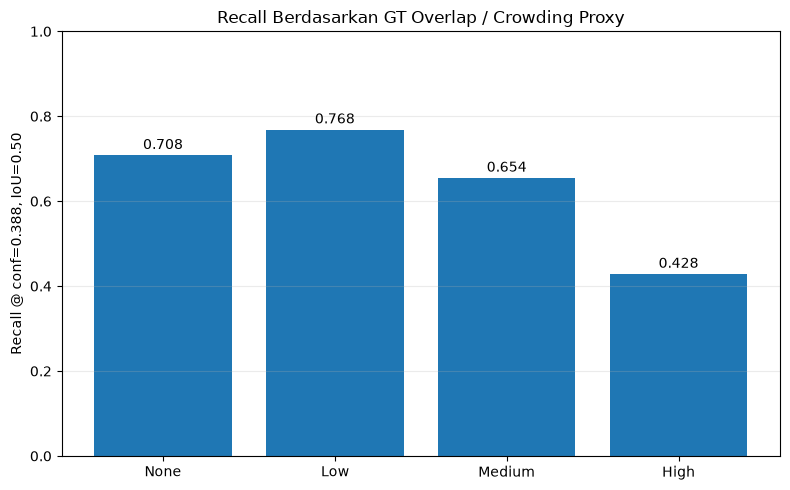

In [51]:
# ============================================================
# FAILURE DIAGNOSTIC 9
# GT OVERLAP / CROWDING PROXY
#
# Proxy:
# max intersection area dengan GT lain
# ------------------------------------
# area target GT
#
# CATATAN:
# ini proxy overlap/crowding,
# BUKAN ground-truth occlusion.
# ============================================================

from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. HELPERS
# ------------------------------------------------------------

def xywh_to_xyxy(box):
    x, y, w, h = box

    return np.array([
        x,
        y,
        x + w,
        y + h,
    ], dtype=float)


def target_overlap_ratio(
    target_box,
    other_box,
):
    """
    Fraction dari area TARGET bbox
    yang beririsan dengan bbox lain.
    """

    a = xywh_to_xyxy(target_box)
    b = xywh_to_xyxy(other_box)

    xa = max(a[0], b[0])
    ya = max(a[1], b[1])

    xb = min(a[2], b[2])
    yb = min(a[3], b[3])

    inter_w = max(
        0.0,
        xb - xa,
    )

    inter_h = max(
        0.0,
        yb - ya,
    )

    intersection = (
        inter_w * inter_h
    )

    target_area = (
        max(0.0, a[2] - a[0])
        * max(0.0, a[3] - a[1])
    )

    if target_area <= 0:
        return 0.0

    return (
        intersection
        / target_area
    )


# ------------------------------------------------------------
# 2. MATCH TP / FN LAGI DAN SIMPAN gt_idx
#
# Ini sengaja dibuat ulang supaya setiap GT memiliki
# identifier object-level yang eksplisit.
# ------------------------------------------------------------

object_records = []


for image in coco_dataset["images"]:

    image_id = image["id"]

    gt_list = gt_by_image.get(
        image_id,
        [],
    )

    pred_list = [
        p
        for p in pred_by_image.get(
            image_id,
            [],
        )
        if p["score"] >= CONF_THRESHOLD
    ]

    pred_list = sorted(
        pred_list,
        key=lambda x: x["score"],
        reverse=True,
    )

    matched_gt = set()


    # --------------------------
    # SAME-CLASS MATCHING
    # --------------------------

    for pred in pred_list:

        best_iou = 0.0
        best_gt_idx = None

        for gt_idx, gt in enumerate(
            gt_list
        ):

            if gt_idx in matched_gt:
                continue

            if (
                pred["category_id"]
                != gt["category_id"]
            ):
                continue

            iou = bbox_iou_xywh(
                pred["bbox"],
                gt["bbox"],
            )

            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx


        if (
            best_gt_idx is not None
            and best_iou >= IOU_THRESHOLD
        ):
            matched_gt.add(
                best_gt_idx
            )


    # --------------------------
    # OVERLAP PER TARGET GT
    # --------------------------

    for gt_idx, gt in enumerate(
        gt_list
    ):

        overlap_values = []

        for other_idx, other_gt in enumerate(
            gt_list
        ):

            if other_idx == gt_idx:
                continue

            overlap_values.append(
                target_overlap_ratio(
                    gt["bbox"],
                    other_gt["bbox"],
                )
            )


        max_overlap = (
            max(overlap_values)
            if overlap_values
            else 0.0
        )

        class_idx = (
            gt["category_id"] - 1
        )


        object_records.append({
            "image_id": image_id,
            "gt_idx": gt_idx,

            "Class":
                CLASS_NAMES[class_idx],

            "Scale":
                get_scale(gt["area"]),

            "Max_GT_Overlap":
                max_overlap,

            "Status":
                (
                    "TP"
                    if gt_idx in matched_gt
                    else "FN"
                ),
        })


overlap_df = pd.DataFrame(
    object_records
)


# ------------------------------------------------------------
# 3. DATA-DRIVEN OVERLAP GROUPS
# ------------------------------------------------------------

positive_overlap = (
    overlap_df.loc[
        overlap_df[
            "Max_GT_Overlap"
        ] > 0,
        "Max_GT_Overlap",
    ]
)


q33_overlap = float(
    positive_overlap.quantile(
        0.33
    )
)

q67_overlap = float(
    positive_overlap.quantile(
        0.67
    )
)


def overlap_group(value):

    if value == 0:
        return "None"

    elif value <= q33_overlap:
        return "Low"

    elif value <= q67_overlap:
        return "Medium"

    else:
        return "High"


overlap_df["Overlap"] = (
    overlap_df[
        "Max_GT_Overlap"
    ].apply(
        overlap_group
    )
)


print("Overlap thresholds")
print("-" * 45)

print("None   : overlap = 0")

print(
    f"Low    : 0 < overlap <= "
    f"{q33_overlap:.4f}"
)

print(
    f"Medium : {q33_overlap:.4f} < overlap <= "
    f"{q67_overlap:.4f}"
)

print(
    f"High   : overlap > "
    f"{q67_overlap:.4f}"
)


# ------------------------------------------------------------
# 4. PERFORMANCE PER OVERLAP GROUP
# ------------------------------------------------------------

overlap_performance = (
    overlap_df
    .groupby(
        "Overlap",
        observed=False,
    )
    .agg(
        GT=("Status", "size"),

        TP=(
            "Status",
            lambda x:
                (x == "TP").sum()
        ),

        FN=(
            "Status",
            lambda x:
                (x == "FN").sum()
        ),

        Mean_Overlap=(
            "Max_GT_Overlap",
            "mean",
        ),
    )
    .reset_index()
)


overlap_performance[
    "Recall"
] = (
    overlap_performance["TP"]
    / overlap_performance["GT"]
)


order = {
    "None": 0,
    "Low": 1,
    "Medium": 2,
    "High": 3,
}


overlap_performance[
    "_order"
] = (
    overlap_performance[
        "Overlap"
    ].map(order)
)


overlap_performance = (
    overlap_performance
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


print(
    "\nDetection performance by GT overlap"
)

display(
    overlap_performance.style
    .format({
        "Mean_Overlap": "{:.4f}",
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 5. GRAPH
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars = ax.bar(
    overlap_performance[
        "Overlap"
    ],
    overlap_performance[
        "Recall"
    ],
)

ax.set_title(
    "Recall Berdasarkan GT Overlap / Crowding Proxy"
)

ax.set_ylabel(
    "Recall @ conf=0.388, IoU=0.50"
)

ax.set_ylim(
    0,
    1,
)

ax.grid(
    axis="y",
    alpha=0.25,
)


for bar, value in zip(
    bars,
    overlap_performance[
        "Recall"
    ],
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,

        value + 0.015,

        f"{value:.3f}",

        ha="center",
    )


plt.tight_layout()

plt.savefig(
    EVAL_DIR
    / "recall_by_gt_overlap_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 6. SAVE
# ------------------------------------------------------------

overlap_df.to_csv(
    EVAL_DIR
    / "object_overlap_diagnostic_seed42.csv",
    index=False,
)

overlap_performance.to_csv(
    EVAL_DIR
    / "overlap_performance_seed42.csv",
    index=False,
)

### Temuan — Pengaruh Overlap / Crowding terhadap Deteksi

Analisis menggunakan proporsi overlap antar-ground-truth bounding box sebagai proxy terhadap kondisi crowding menunjukkan penurunan recall yang kuat ketika tingkat overlap meningkat.

Objek tanpa overlap menghasilkan recall sebesar **0,7078**, sedangkan kelompok *low overlap* mencapai **0,7682**. Namun, recall menurun menjadi **0,6545** pada kelompok *medium overlap* dan turun secara tajam menjadi hanya **0,4282** pada kelompok *high overlap*.

Kelompok *high overlap* memiliki rata-rata proporsi overlap sebesar **0,4127**, yang berarti rata-rata sekitar 41% area bounding box target beririsan dengan bounding box ground-truth lain. Pada kelompok ini, dari **4.115 objek**, hanya **1.762 objek** yang berhasil dideteksi dan **2.353 objek** menjadi false negative.

Hasil ini menunjukkan bahwa **local crowding/overlap merupakan salah satu kondisi yang sangat berkaitan dengan kegagalan baseline YOLO26n**. Temuan ini berbeda dari analisis jumlah objek per citra sebelumnya, yang tidak menunjukkan penurunan performa pada citra dengan density tinggi. Dengan demikian, kesulitan model tampaknya lebih berkaitan dengan **kedekatan dan tumpang tindih antarobjek** daripada sekadar banyaknya objek dalam satu citra.

Namun, nilai overlap yang digunakan merupakan **proxy geometris berdasarkan bounding box**, bukan anotasi occlusion sebenarnya. Oleh karena itu, hasil ini tidak dapat digunakan untuk menyatakan bahwa occlusion merupakan penyebab kausal secara langsung. Analisis visual terhadap contoh high-overlap serta analisis interaksi dengan skala objek masih diperlukan.

Temuan sementara menunjukkan dua failure condition utama baseline, yaitu **small-object detection** dan **high-overlap/crowded objects**.

Brightness thresholds
---------------------------------------------
Dark   : brightness <= 91.66
Medium : 91.66 < brightness <= 115.96
Bright : brightness > 115.96

Image distribution


Brightness Group,Images
Dark,591
Medium,608
Bright,591



Detection performance by brightness


Brightness_Group,GT,TP,FN,Mean_Brightness,Recall
Dark,4804,2264,2540,83.87,0.4713
Medium,13048,8702,4346,109.34,0.6669
Bright,14224,10610,3614,120.05,0.7459


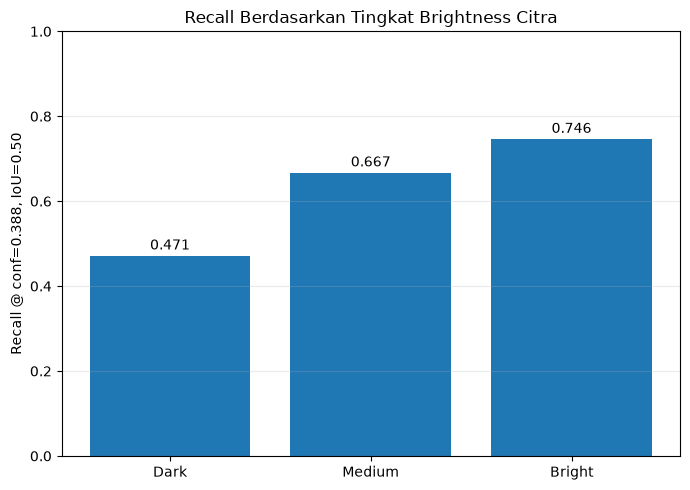

In [53]:
# ============================================================
# FAILURE DIAGNOSTIC 10 — IMAGE BRIGHTNESS
# Dark / Medium / Bright
#
# CATATAN:
# Brightness hanya proxy kondisi pencahayaan.
# BUKAN ground-truth label siang / malam.
# ============================================================

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. HITUNG MEAN BRIGHTNESS SETIAP IMAGE
# ------------------------------------------------------------

brightness_records = []


for img_info in coco_dataset["images"]:

    image_id = img_info["id"]
    file_name = img_info["file_name"]

    image_path = (
        VAL_IMAGES / file_name
    )

    img = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE,
    )

    if img is None:
        raise FileNotFoundError(
            f"Gagal membaca: {image_path}"
        )

    mean_brightness = float(
        img.mean()
    )

    brightness_records.append({
        "image_id": image_id,
        "file_name": file_name,
        "Brightness": mean_brightness,
    })


brightness_image_df = pd.DataFrame(
    brightness_records
)


# ------------------------------------------------------------
# 2. DATA-DRIVEN THRESHOLD
# ------------------------------------------------------------

q33_brightness = float(
    brightness_image_df[
        "Brightness"
    ].quantile(0.33)
)

q67_brightness = float(
    brightness_image_df[
        "Brightness"
    ].quantile(0.67)
)


def brightness_group(value):

    if value <= q33_brightness:
        return "Dark"

    elif value <= q67_brightness:
        return "Medium"

    else:
        return "Bright"


brightness_image_df[
    "Brightness_Group"
] = (
    brightness_image_df[
        "Brightness"
    ].apply(
        brightness_group
    )
)


print("Brightness thresholds")
print("-" * 45)

print(
    f"Dark   : brightness <= "
    f"{q33_brightness:.2f}"
)

print(
    f"Medium : {q33_brightness:.2f} < brightness <= "
    f"{q67_brightness:.2f}"
)

print(
    f"Bright : brightness > "
    f"{q67_brightness:.2f}"
)


# ------------------------------------------------------------
# 3. IMAGE DISTRIBUTION
# ------------------------------------------------------------

brightness_distribution = (
    brightness_image_df[
        "Brightness_Group"
    ]
    .value_counts()
    .reindex([
        "Dark",
        "Medium",
        "Bright",
    ])
    .reset_index()
)

brightness_distribution.columns = [
    "Brightness Group",
    "Images",
]


print(
    "\nImage distribution"
)

display(
    brightness_distribution.style
    .hide(axis="index")
)


# ------------------------------------------------------------
# 4. JOIN DENGAN OBJECT-LEVEL TP/FN
# ------------------------------------------------------------

brightness_map = dict(
    zip(
        brightness_image_df["image_id"],
        brightness_image_df[
            "Brightness_Group"
        ],
    )
)


brightness_value_map = dict(
    zip(
        brightness_image_df["image_id"],
        brightness_image_df[
            "Brightness"
        ],
    )
)


brightness_diag_df = (
    object_records.copy()
    if isinstance(object_records, list)
    else object_records.copy()
)

brightness_diag_df = pd.DataFrame(
    brightness_diag_df
)


brightness_diag_df[
    "Brightness_Group"
] = (
    brightness_diag_df[
        "image_id"
    ].map(
        brightness_map
    )
)

brightness_diag_df[
    "Brightness"
] = (
    brightness_diag_df[
        "image_id"
    ].map(
        brightness_value_map
    )
)


# ------------------------------------------------------------
# 5. PERFORMANCE PER BRIGHTNESS GROUP
# ------------------------------------------------------------

brightness_performance = (
    brightness_diag_df
    .groupby(
        "Brightness_Group",
        observed=False,
    )
    .agg(
        GT=("Status", "size"),

        TP=(
            "Status",
            lambda x:
                (x == "TP").sum()
        ),

        FN=(
            "Status",
            lambda x:
                (x == "FN").sum()
        ),

        Mean_Brightness=(
            "Brightness",
            "mean",
        ),
    )
    .reset_index()
)


brightness_performance[
    "Recall"
] = (
    brightness_performance["TP"]
    / brightness_performance["GT"]
)


brightness_order = {
    "Dark": 0,
    "Medium": 1,
    "Bright": 2,
}

brightness_performance[
    "_order"
] = (
    brightness_performance[
        "Brightness_Group"
    ].map(
        brightness_order
    )
)


brightness_performance = (
    brightness_performance
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


print(
    "\nDetection performance by brightness"
)

display(
    brightness_performance.style
    .format({
        "Mean_Brightness": "{:.2f}",
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 6. GRAPH
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 5)
)

bars = ax.bar(
    brightness_performance[
        "Brightness_Group"
    ],
    brightness_performance[
        "Recall"
    ],
)

ax.set_title(
    "Recall Berdasarkan Tingkat Brightness Citra"
)

ax.set_ylabel(
    "Recall @ conf=0.388, IoU=0.50"
)

ax.set_ylim(
    0,
    1,
)

ax.grid(
    axis="y",
    alpha=0.25,
)


for bar, value in zip(
    bars,
    brightness_performance[
        "Recall"
    ],
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,

        value + 0.015,

        f"{value:.3f}",

        ha="center",
    )


plt.tight_layout()

plt.savefig(
    EVAL_DIR
    / "recall_by_brightness_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 7. SAVE
# ------------------------------------------------------------

brightness_image_df.to_csv(
    EVAL_DIR
    / "image_brightness_seed42.csv",
    index=False,
)

brightness_performance.to_csv(
    EVAL_DIR
    / "brightness_performance_seed42.csv",
    index=False,
)

### Temuan — Pengaruh Brightness terhadap Deteksi

Evaluasi berdasarkan tingkat brightness citra menunjukkan adanya hubungan yang kuat antara kondisi pencahayaan dan kemampuan deteksi baseline YOLO26n.

Kelompok citra *dark* menghasilkan recall paling rendah, yaitu **0,4713**, dengan **2.540 false negative dari 4.804 ground-truth object**. Recall kemudian meningkat menjadi **0,6669** pada kelompok *medium* dan mencapai **0,7459** pada kelompok *bright*.

Dengan demikian, terdapat selisih recall sekitar **0,275 poin** antara kelompok dark dan bright. Pola peningkatan recall yang konsisten dari dark → medium → bright menunjukkan bahwa **kondisi visual dengan brightness rendah merupakan salah satu failure condition penting baseline YOLO26n** pada validation set.

Namun, brightness pada analisis ini merupakan ukuran luminance rata-rata citra dan **bukan anotasi langsung kondisi siang atau malam**. Oleh karena itu, hasil ini hanya menunjukkan asosiasi dengan kondisi pencahayaan rendah dan tidak dapat secara langsung diinterpretasikan sebagai kegagalan khusus pada kondisi malam hari.

Selain itu, distribusi kelas, skala objek, dan tingkat overlap dapat berbeda antar kelompok brightness. Analisis interaksi diperlukan untuk menentukan apakah penurunan pada citra gelap terjadi secara umum atau terutama pada objek kecil dan/atau objek yang saling overlap.

Recall berdasarkan Scale × GT Overlap


Scale,Overlap,GT,TP,FN,Recall
Small,None,15947,10580,5367,0.6634
Small,Low,2706,1886,820,0.6970
Small,Medium,3190,1856,1334,0.5818
Small,High,3550,1337,2213,0.3766
Medium,None,3435,3092,343,0.9001
Medium,Low,1218,1096,122,0.8998
Medium,Medium,958,840,118,0.8768
Medium,High,486,356,130,0.7325
Large,None,223,205,18,0.9193
Large,Low,192,180,12,0.9375



Small-object performance by overlap


Scale,Overlap,GT,TP,FN,Recall
Small,None,15947,10580,5367,0.6634
Small,Low,2706,1886,820,0.6970
Small,Medium,3190,1856,1334,0.5818
Small,High,3550,1337,2213,0.3766


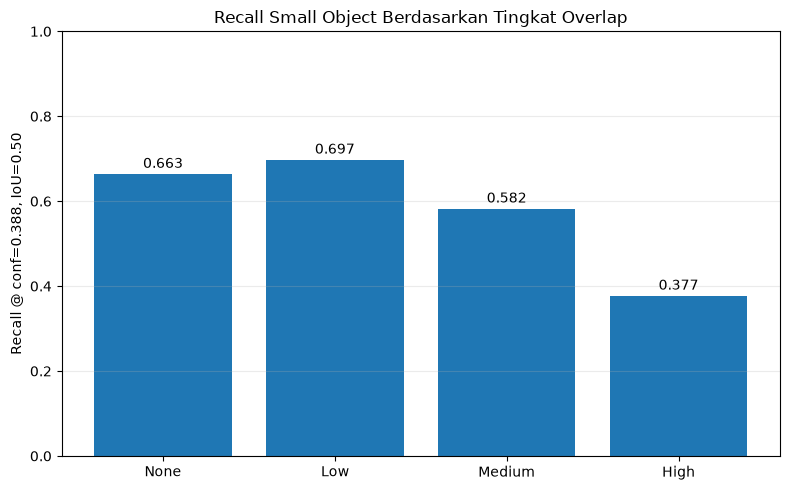

In [54]:
# ============================================================
# FAILURE DIAGNOSTIC 11
# INTERACTION: SCALE × GT OVERLAP
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. AGGREGATE
# overlap_df sudah punya:
# Class, Scale, Overlap, Status
# ------------------------------------------------------------

scale_overlap_perf = (
    overlap_df
    .groupby(
        ["Scale", "Overlap"],
        observed=False,
    )
    .agg(
        GT=("Status", "size"),

        TP=(
            "Status",
            lambda x: (x == "TP").sum()
        ),

        FN=(
            "Status",
            lambda x: (x == "FN").sum()
        ),
    )
    .reset_index()
)


scale_overlap_perf["Recall"] = (
    scale_overlap_perf["TP"]
    / scale_overlap_perf["GT"]
)


# ------------------------------------------------------------
# 2. SORT
# ------------------------------------------------------------

scale_order = {
    "Small": 0,
    "Medium": 1,
    "Large": 2,
}

overlap_order = {
    "None": 0,
    "Low": 1,
    "Medium": 2,
    "High": 3,
}


scale_overlap_perf["_scale"] = (
    scale_overlap_perf["Scale"]
    .map(scale_order)
)

scale_overlap_perf["_overlap"] = (
    scale_overlap_perf["Overlap"]
    .map(overlap_order)
)


scale_overlap_perf = (
    scale_overlap_perf
    .sort_values(
        ["_scale", "_overlap"]
    )
    .drop(
        columns=[
            "_scale",
            "_overlap",
        ]
    )
    .reset_index(drop=True)
)


print(
    "Recall berdasarkan Scale × GT Overlap"
)

display(
    scale_overlap_perf.style
    .format({
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 3. SMALL OBJECT SAJA
# ------------------------------------------------------------

small_overlap_perf = (
    scale_overlap_perf[
        scale_overlap_perf["Scale"]
        == "Small"
    ]
    .copy()
)


print(
    "\nSmall-object performance by overlap"
)

display(
    small_overlap_perf.style
    .format({
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 4. GRAPH — SMALL OBJECT ONLY
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars = ax.bar(
    small_overlap_perf["Overlap"],
    small_overlap_perf["Recall"],
)

ax.set_title(
    "Recall Small Object Berdasarkan Tingkat Overlap"
)

ax.set_ylabel(
    "Recall @ conf=0.388, IoU=0.50"
)

ax.set_ylim(
    0,
    1,
)

ax.grid(
    axis="y",
    alpha=0.25,
)


for bar, value in zip(
    bars,
    small_overlap_perf["Recall"],
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,

        value + 0.015,

        f"{value:.3f}",

        ha="center",
    )


plt.tight_layout()

plt.savefig(
    EVAL_DIR
    / "small_object_recall_by_overlap_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 5. SAVE
# ------------------------------------------------------------

scale_overlap_perf.to_csv(
    EVAL_DIR
    / "scale_overlap_interaction_seed42.csv",
    index=False,
)

### Temuan — Interaksi Skala Objek dan Overlap

Analisis interaksi antara skala objek dan tingkat overlap menunjukkan bahwa pengaruh overlap terhadap kemampuan deteksi berbeda secara substansial menurut ukuran objek.

Pada objek *small*, recall sebesar **0,6634** ketika tidak terdapat overlap dan **0,6970** pada overlap rendah. Namun, recall menurun menjadi **0,5818** pada overlap medium dan hanya **0,3766** pada kondisi high-overlap. Dengan demikian, terdapat penurunan sekitar **0,287 poin recall** antara objek kecil tanpa overlap dan objek kecil dengan overlap tinggi.

Dampak overlap juga terlihat pada objek medium, tetapi lebih kecil. Recall medium menurun dari **0,9001** pada kondisi tanpa overlap menjadi **0,7325** pada high-overlap. Pada objek large, perubahan relatif lebih kecil, dari **0,9193** menjadi **0,8734**, walaupun jumlah sampel large jauh lebih sedikit sehingga interpretasinya perlu dilakukan secara hati-hati.

Dari **2.353 false negative** yang sebelumnya ditemukan pada kelompok high-overlap, sebanyak **2.213 kasus atau sekitar 94%** berasal dari objek berukuran small. Hal ini menunjukkan bahwa kegagalan pada kondisi overlap tinggi sangat terkonsentrasi pada objek kecil.

Temuan ini mempersempit failure profile baseline dari dua faktor terpisah, yaitu small-object detection dan crowding, menjadi sebuah kondisi yang lebih spesifik: **deteksi objek kecil pada kondisi overlap/crowding tinggi merupakan salah satu failure condition utama YOLO26n pada validation set**.

Meskipun demikian, overlap bounding box tetap merupakan proxy geometris terhadap crowding dan tidak dapat dianggap sebagai anotasi occlusion sebenarnya. Selain itu, komposisi kelas pada setiap kombinasi skala-overlap masih dapat menjadi faktor perancu.

Recall berdasarkan Scale × Brightness


Scale,Brightness_Group,GT,TP,FN,Recall
Small,Dark,3878,1553,2325,0.4005
Small,Medium,10200,6195,4005,0.6074
Small,Bright,11315,7911,3404,0.6992
Medium,Dark,895,690,205,0.7709
Medium,Medium,2519,2202,317,0.8742
Medium,Bright,2683,2492,191,0.9288
Large,Dark,31,21,10,0.6774
Large,Medium,329,305,24,0.9271
Large,Bright,226,207,19,0.9159



Small-object performance by brightness


Scale,Brightness_Group,GT,TP,FN,Recall
Small,Dark,3878,1553,2325,0.4005
Small,Medium,10200,6195,4005,0.6074
Small,Bright,11315,7911,3404,0.6992


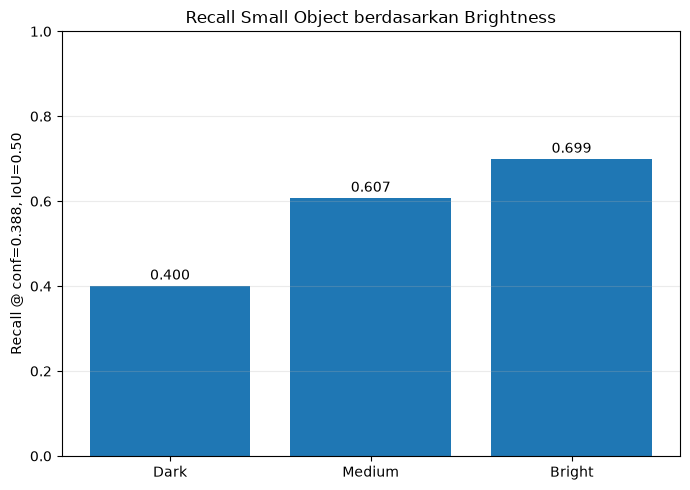

In [55]:
# ============================================================
# FAILURE DIAGNOSTIC 12
# INTERACTION: SCALE × BRIGHTNESS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt


# brightness_diag_df sudah berisi:
# Scale, Status, Brightness_Group

scale_brightness_perf = (
    brightness_diag_df
    .groupby(
        ["Scale", "Brightness_Group"],
        observed=False,
    )
    .agg(
        GT=("Status", "size"),

        TP=(
            "Status",
            lambda x: (x == "TP").sum()
        ),

        FN=(
            "Status",
            lambda x: (x == "FN").sum()
        ),
    )
    .reset_index()
)


scale_brightness_perf["Recall"] = (
    scale_brightness_perf["TP"]
    / scale_brightness_perf["GT"]
)


# ------------------------------------------------------------
# SORT
# ------------------------------------------------------------

scale_order = {
    "Small": 0,
    "Medium": 1,
    "Large": 2,
}

brightness_order = {
    "Dark": 0,
    "Medium": 1,
    "Bright": 2,
}


scale_brightness_perf["_scale"] = (
    scale_brightness_perf["Scale"]
    .map(scale_order)
)

scale_brightness_perf["_brightness"] = (
    scale_brightness_perf["Brightness_Group"]
    .map(brightness_order)
)


scale_brightness_perf = (
    scale_brightness_perf
    .sort_values(
        ["_scale", "_brightness"]
    )
    .drop(
        columns=[
            "_scale",
            "_brightness",
        ]
    )
    .reset_index(drop=True)
)


print(
    "Recall berdasarkan Scale × Brightness"
)

display(
    scale_brightness_perf.style
    .format({
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# SMALL OBJECT ONLY
# ------------------------------------------------------------

small_brightness_perf = (
    scale_brightness_perf[
        scale_brightness_perf["Scale"]
        == "Small"
    ]
    .copy()
)


print(
    "\nSmall-object performance by brightness"
)

display(
    small_brightness_perf.style
    .format({
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# GRAPH
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 5)
)

bars = ax.bar(
    small_brightness_perf[
        "Brightness_Group"
    ],
    small_brightness_perf[
        "Recall"
    ],
)

ax.set_title(
    "Recall Small Object berdasarkan Brightness"
)

ax.set_ylabel(
    "Recall @ conf=0.388, IoU=0.50"
)

ax.set_ylim(
    0,
    1,
)

ax.grid(
    axis="y",
    alpha=0.25,
)


for bar, value in zip(
    bars,
    small_brightness_perf["Recall"],
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,

        value + 0.015,

        f"{value:.3f}",

        ha="center",
    )


plt.tight_layout()

plt.savefig(
    EVAL_DIR
    / "small_object_recall_by_brightness_seed42.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

scale_brightness_perf.to_csv(
    EVAL_DIR
    / "scale_brightness_interaction_seed42.csv",
    index=False,
)

### Temuan — Interaksi Skala Objek dan Brightness

Analisis interaksi antara skala objek dan brightness menunjukkan bahwa kondisi pencahayaan rendah sangat berkaitan dengan penurunan kemampuan deteksi pada objek kecil.

Pada objek berukuran *small*, recall hanya mencapai **0,4005** pada kelompok *dark*. Recall meningkat menjadi **0,6074** pada kelompok *medium* dan mencapai **0,6992** pada kelompok *bright*. Dengan demikian, terdapat perbedaan sekitar **0,299 poin recall** antara small object pada citra dark dan bright.

Dari **3.878 small object** pada kelompok dark, sebanyak **2.325 objek menjadi false negative**, sehingga lebih dari separuh objek kecil pada kondisi brightness rendah tidak berhasil dideteksi pada operating point yang digunakan.

Hasil ini menunjukkan bahwa kelemahan small-object detection tidak hanya berkaitan dengan ukuran objek itu sendiri, tetapi semakin berat pada kondisi visual dengan brightness rendah. Dengan demikian, salah satu failure condition yang paling menonjol adalah **small-object detection under low-brightness conditions**.

Namun, brightness merupakan proxy luminance citra dan bukan anotasi eksplisit siang/malam. Selain itu, komposisi kelas dan tingkat overlap masih dapat berbeda antar kelompok brightness. Oleh karena itu, analisis per kelas diperlukan untuk mengetahui kelas mana yang paling terdampak oleh kondisi brightness rendah.

In [56]:
# ============================================================
# FAILURE DIAGNOSTIC 13
# INTERACTION: CLASS × BRIGHTNESS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt


class_brightness_perf = (
    brightness_diag_df
    .groupby(
        ["Class", "Brightness_Group"],
        observed=False,
    )
    .agg(
        GT=("Status", "size"),

        TP=(
            "Status",
            lambda x: (x == "TP").sum()
        ),

        FN=(
            "Status",
            lambda x: (x == "FN").sum()
        ),
    )
    .reset_index()
)


class_brightness_perf["Recall"] = (
    class_brightness_perf["TP"]
    / class_brightness_perf["GT"]
)


# ------------------------------------------------------------
# SORT
# ------------------------------------------------------------

class_order = {
    name: i
    for i, name in enumerate(CLASS_NAMES)
}

brightness_order = {
    "Dark": 0,
    "Medium": 1,
    "Bright": 2,
}


class_brightness_perf["_class"] = (
    class_brightness_perf["Class"]
    .map(class_order)
)

class_brightness_perf["_brightness"] = (
    class_brightness_perf["Brightness_Group"]
    .map(brightness_order)
)


class_brightness_perf = (
    class_brightness_perf
    .sort_values(
        ["_class", "_brightness"]
    )
    .drop(
        columns=[
            "_class",
            "_brightness",
        ]
    )
    .reset_index(drop=True)
)


print(
    "Recall berdasarkan Class × Brightness"
)

display(
    class_brightness_perf.style
    .format({
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# PIVOT TABLE — EASIER TO READ
# ------------------------------------------------------------

class_brightness_pivot = (
    class_brightness_perf
    .pivot(
        index="Class",
        columns="Brightness_Group",
        values="Recall",
    )
    .reindex(
        index=CLASS_NAMES,
        columns=[
            "Dark",
            "Medium",
            "Bright",
        ],
    )
)


print(
    "\nRecall matrix — Class × Brightness"
)

display(
    class_brightness_pivot.style
    .format("{:.4f}")
)


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

class_brightness_perf.to_csv(
    EVAL_DIR
    / "class_brightness_interaction_seed42.csv",
    index=False,
)

Recall berdasarkan Class × Brightness


Class,Brightness_Group,GT,TP,FN,Recall
Bus,Dark,6,3,3,0.5000
Bus,Medium,31,27,4,0.8710
Bus,Bright,60,42,18,0.7000
Mobil Penumpang,Dark,1778,1271,507,0.7148
Mobil Penumpang,Medium,4298,3558,740,0.8278
Mobil Penumpang,Bright,4948,4343,605,0.8777
Pejalan Kaki,Dark,85,19,66,0.2235
Pejalan Kaki,Medium,501,268,233,0.5349
Pejalan Kaki,Bright,360,181,179,0.5028
Sepeda Motor,Dark,2824,908,1916,0.3215



Recall matrix — Class × Brightness


Brightness_Group,Dark,Medium,Bright
Class,,,
Bus,0.5000,0.8710,0.7000
Mobil Penumpang,0.7148,0.8278,0.8777
Pejalan Kaki,0.2235,0.5349,0.5028
Sepeda Motor,0.3215,0.5733,0.6774
Truck,0.5676,0.7930,0.7795
Unmotorized,nan,0.5385,0.6667


### Temuan — Interaksi Kelas dan Brightness

Analisis per kelas menunjukkan bahwa pengaruh brightness terhadap deteksi bersifat **class-dependent**.

Kelas **Sepeda Motor** menunjukkan pola paling jelas. Recall meningkat secara konsisten dari **0,3215 pada kondisi dark**, menjadi **0,5733 pada medium**, dan **0,6774 pada bright**. Pada kelompok dark, terdapat 2.824 ground-truth Sepeda Motor dan 1.916 di antaranya menjadi false negative. Dengan demikian, Sepeda Motor merupakan kontributor terbesar terhadap kegagalan deteksi pada kondisi brightness rendah.

Kelas **Pejalan Kaki** juga mengalami penurunan performa yang sangat kuat pada kondisi dark, dengan recall hanya **0,2235**, dibandingkan **0,5349** pada medium dan **0,5028** pada bright. Tidak adanya peningkatan dari medium ke bright menunjukkan bahwa kelemahan Pejalan Kaki tidak dapat dijelaskan oleh brightness saja dan kemungkinan melibatkan karakteristik kelas atau kondisi visual lainnya.

Sebaliknya, **Mobil Penumpang** tetap memiliki recall relatif tinggi pada kondisi dark sebesar **0,7148**, kemudian meningkat menjadi **0,8278** pada medium dan **0,8777** pada bright. Hal ini kembali menunjukkan bahwa kondisi brightness rendah tidak mempengaruhi seluruh kelas secara seragam.

Kelas **Truck** juga mengalami penurunan pada kondisi dark, dengan recall **0,5676**, dibandingkan sekitar **0,79** pada kelompok medium dan bright.

Hasil ini memperkuat indikasi bahwa kondisi visual dengan brightness rendah terutama bermasalah untuk kelas tertentu, khususnya **Sepeda Motor dan Pejalan Kaki**. Namun, brightness merupakan proxy terhadap luminance citra dan bukan anotasi eksplisit kondisi siang atau malam, sehingga hasil ini tidak dapat langsung ditafsirkan sebagai performa siang-versus-malam.

Selain itu, karena distribusi skala objek berbeda antar kelas, analisis selanjutnya diperlukan untuk mengetahui apakah rendahnya recall pada kondisi dark terutama berasal dari **objek kecil pada kelas tertentu**.

In [57]:
# ============================================================
# FAILURE DIAGNOSTIC 14
# CLASS × SCALE × BRIGHTNESS
# Fokus utama: SMALL OBJECT
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. AGGREGATE
# ------------------------------------------------------------

class_scale_brightness = (
    brightness_diag_df
    .groupby(
        [
            "Class",
            "Scale",
            "Brightness_Group",
        ],
        observed=False,
    )
    .agg(
        GT=("Status", "size"),

        TP=(
            "Status",
            lambda x:
                (x == "TP").sum()
        ),

        FN=(
            "Status",
            lambda x:
                (x == "FN").sum()
        ),
    )
    .reset_index()
)


class_scale_brightness[
    "Recall"
] = (
    class_scale_brightness["TP"]
    / class_scale_brightness["GT"]
)


# ------------------------------------------------------------
# 2. FOCUS: SMALL OBJECT
# ------------------------------------------------------------

small_class_brightness = (
    class_scale_brightness[
        class_scale_brightness["Scale"]
        == "Small"
    ]
    .copy()
)


brightness_order = {
    "Dark": 0,
    "Medium": 1,
    "Bright": 2,
}

class_order = {
    name: i
    for i, name in enumerate(
        CLASS_NAMES
    )
}


small_class_brightness[
    "_class"
] = (
    small_class_brightness[
        "Class"
    ].map(class_order)
)

small_class_brightness[
    "_brightness"
] = (
    small_class_brightness[
        "Brightness_Group"
    ].map(brightness_order)
)


small_class_brightness = (
    small_class_brightness
    .sort_values([
        "_class",
        "_brightness",
    ])
    .drop(columns=[
        "_class",
        "_brightness",
    ])
    .reset_index(drop=True)
)


print(
    "SMALL OBJECT — Class × Brightness"
)

display(
    small_class_brightness.style
    .format({
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 3. RECALL MATRIX
# ------------------------------------------------------------

small_recall_pivot = (
    small_class_brightness
    .pivot(
        index="Class",
        columns="Brightness_Group",
        values="Recall",
    )
    .reindex(
        index=CLASS_NAMES,
        columns=[
            "Dark",
            "Medium",
            "Bright",
        ],
    )
)


print(
    "\nRecall matrix — SMALL Class × Brightness"
)

display(
    small_recall_pivot.style
    .format("{:.4f}")
)


# ------------------------------------------------------------
# 4. GT COUNT MATRIX
# supaya sparse cells tidak salah ditafsirkan
# ------------------------------------------------------------

small_gt_pivot = (
    small_class_brightness
    .pivot(
        index="Class",
        columns="Brightness_Group",
        values="GT",
    )
    .reindex(
        index=CLASS_NAMES,
        columns=[
            "Dark",
            "Medium",
            "Bright",
        ],
    )
)


print(
    "\nGT count matrix — SMALL Class × Brightness"
)

display(
    small_gt_pivot
)


# ------------------------------------------------------------
# 5. SAVE
# ------------------------------------------------------------

small_class_brightness.to_csv(
    EVAL_DIR
    / "small_class_brightness_interaction_seed42.csv",
    index=False,
)

SMALL OBJECT — Class × Brightness


Class,Scale,Brightness_Group,GT,TP,FN,Recall
Bus,Small,Bright,6,1,5,0.1667
Mobil Penumpang,Small,Dark,1079,696,383,0.6450
Mobil Penumpang,Small,Medium,2613,2014,599,0.7708
Mobil Penumpang,Small,Bright,3236,2704,532,0.8356
Pejalan Kaki,Small,Dark,85,19,66,0.2235
Pejalan Kaki,Small,Medium,485,260,225,0.5361
Pejalan Kaki,Small,Bright,345,176,169,0.5101
Sepeda Motor,Small,Dark,2702,836,1866,0.3094
Sepeda Motor,Small,Medium,7007,3886,3121,0.5546
Sepeda Motor,Small,Bright,7608,4986,2622,0.6554



Recall matrix — SMALL Class × Brightness


Brightness_Group,Dark,Medium,Bright
Class,,,
Bus,nan,nan,0.1667
Mobil Penumpang,0.6450,0.7708,0.8356
Pejalan Kaki,0.2235,0.5361,0.5101
Sepeda Motor,0.3094,0.5546,0.6554
Truck,0.1667,0.3846,0.3832
Unmotorized,nan,0.0000,0.2308



GT count matrix — SMALL Class × Brightness


Brightness_Group,Dark,Medium,Bright
Class,,,
Bus,NaN,NaN,6.0
Mobil Penumpang,1079.0,2613.0,3236.0
Pejalan Kaki,85.0,485.0,345.0
Sepeda Motor,2702.0,7007.0,7608.0
Truck,12.0,91.0,107.0
Unmotorized,NaN,4.0,13.0


### Temuan — Interaksi Kelas, Skala, dan Brightness

Analisis tiga faktor menunjukkan bahwa pengaruh brightness terhadap kemampuan deteksi tetap terlihat setelah skala dan kelas objek dikontrol.

Temuan paling kuat terdapat pada **Sepeda Motor berukuran small**. Recall pada kondisi dark hanya mencapai **0,3094** dari 2.702 ground-truth object. Recall meningkat menjadi **0,5546** pada kondisi medium dan **0,6554** pada kondisi bright. Dengan demikian, terdapat selisih sekitar **0,346 poin recall** antara small motorcycle pada kondisi dark dan bright.

Hasil tersebut penting karena perbandingan dilakukan pada kelas dan skala objek yang sama. Oleh karena itu, penurunan performa tidak dapat dijelaskan hanya oleh perbedaan proporsi kelas atau dominasi small object pada kelompok brightness tertentu.

Kelas **Pejalan Kaki-small** juga menunjukkan pola serupa, dengan recall hanya **0,2235** pada kondisi dark dibandingkan **0,5101** pada kondisi bright. Namun, jumlah ground-truth Pejalan Kaki-small pada kondisi dark hanya 85 objek sehingga hasil ini perlu ditafsirkan lebih hati-hati.

Untuk **Mobil Penumpang-small**, recall juga meningkat dari **0,6450 pada dark** menjadi **0,8356 pada bright**, tetapi performanya secara absolut masih jauh lebih tinggi dibandingkan Sepeda Motor dan Pejalan Kaki. Hal ini kembali menunjukkan bahwa efek adverse visual condition bersifat class-dependent.

Dari 2.325 false negative small-object pada kelompok dark, sebanyak **1.866 kasus (~80,3%)** berasal dari Sepeda Motor. Meskipun sebagian dominasi tersebut dipengaruhi oleh tingginya jumlah Sepeda Motor dalam kelompok tersebut, perbandingan intra-kelas tetap menunjukkan penurunan recall yang substansial pada kondisi brightness rendah.

Secara keseluruhan, hasil ini mempersempit salah satu failure condition utama baseline menjadi **deteksi Sepeda Motor berukuran kecil pada kondisi brightness rendah**. Namun, brightness tetap merupakan proxy luminance dan bukan anotasi eksplisit kondisi malam hari.

In [58]:
# ============================================================
# FAILURE DIAGNOSTIC 15
# SMALL OBJECT × BRIGHTNESS × OVERLAP
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Tambahkan brightness ke overlap_df
#
# overlap_df sudah object-level dan punya:
# image_id, gt_idx, Class, Scale,
# Max_GT_Overlap, Overlap, Status
# ------------------------------------------------------------

triple_df = overlap_df.copy()

triple_df["Brightness_Group"] = (
    triple_df["image_id"]
    .map(brightness_map)
)


# ------------------------------------------------------------
# 2. FOKUS SMALL OBJECT
# ------------------------------------------------------------

small_triple_df = (
    triple_df[
        triple_df["Scale"] == "Small"
    ]
    .copy()
)


# ------------------------------------------------------------
# 3. BRIGHTNESS × OVERLAP
# ------------------------------------------------------------

small_brightness_overlap = (
    small_triple_df
    .groupby(
        [
            "Brightness_Group",
            "Overlap",
        ],
        observed=False,
    )
    .agg(
        GT=("Status", "size"),

        TP=(
            "Status",
            lambda x:
                (x == "TP").sum()
        ),

        FN=(
            "Status",
            lambda x:
                (x == "FN").sum()
        ),
    )
    .reset_index()
)


small_brightness_overlap["Recall"] = (
    small_brightness_overlap["TP"]
    / small_brightness_overlap["GT"]
)


# ------------------------------------------------------------
# 4. SORT
# ------------------------------------------------------------

brightness_order = {
    "Dark": 0,
    "Medium": 1,
    "Bright": 2,
}

overlap_order = {
    "None": 0,
    "Low": 1,
    "Medium": 2,
    "High": 3,
}


small_brightness_overlap["_b"] = (
    small_brightness_overlap[
        "Brightness_Group"
    ].map(brightness_order)
)

small_brightness_overlap["_o"] = (
    small_brightness_overlap[
        "Overlap"
    ].map(overlap_order)
)


small_brightness_overlap = (
    small_brightness_overlap
    .sort_values(
        ["_b", "_o"]
    )
    .drop(
        columns=["_b", "_o"]
    )
    .reset_index(drop=True)
)


print(
    "SMALL OBJECT — Brightness × Overlap"
)

display(
    small_brightness_overlap.style
    .format({
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# 5. RECALL MATRIX
# ------------------------------------------------------------

triple_recall_pivot = (
    small_brightness_overlap
    .pivot(
        index="Brightness_Group",
        columns="Overlap",
        values="Recall",
    )
    .reindex(
        index=[
            "Dark",
            "Medium",
            "Bright",
        ],
        columns=[
            "None",
            "Low",
            "Medium",
            "High",
        ],
    )
)


print(
    "\nRecall matrix — SMALL × Brightness × Overlap"
)

display(
    triple_recall_pivot.style
    .format("{:.4f}")
)


# ------------------------------------------------------------
# 6. GT COUNTS — WAJIB DILIHAT
# ------------------------------------------------------------

triple_gt_pivot = (
    small_brightness_overlap
    .pivot(
        index="Brightness_Group",
        columns="Overlap",
        values="GT",
    )
    .reindex(
        index=[
            "Dark",
            "Medium",
            "Bright",
        ],
        columns=[
            "None",
            "Low",
            "Medium",
            "High",
        ],
    )
)


print(
    "\nGT count matrix"
)

display(
    triple_gt_pivot
)


# ------------------------------------------------------------
# 7. KHUSUS SMALL MOTORCYCLE
# ------------------------------------------------------------

motor_small_df = (
    small_triple_df[
        small_triple_df["Class"]
        == "Sepeda Motor"
    ]
)


motor_condition_perf = (
    motor_small_df
    .groupby(
        [
            "Brightness_Group",
            "Overlap",
        ],
        observed=False,
    )
    .agg(
        GT=("Status", "size"),

        TP=(
            "Status",
            lambda x:
                (x == "TP").sum()
        ),

        FN=(
            "Status",
            lambda x:
                (x == "FN").sum()
        ),
    )
    .reset_index()
)


motor_condition_perf["Recall"] = (
    motor_condition_perf["TP"]
    / motor_condition_perf["GT"]
)


motor_condition_perf["_b"] = (
    motor_condition_perf[
        "Brightness_Group"
    ].map(brightness_order)
)

motor_condition_perf["_o"] = (
    motor_condition_perf[
        "Overlap"
    ].map(overlap_order)
)


motor_condition_perf = (
    motor_condition_perf
    .sort_values(
        ["_b", "_o"]
    )
    .drop(
        columns=["_b", "_o"]
    )
    .reset_index(drop=True)
)


print(
    "\nSMALL SEPEDA MOTOR — Brightness × Overlap"
)

display(
    motor_condition_perf.style
    .format({
        "Recall": "{:.4f}",
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

small_brightness_overlap.to_csv(
    EVAL_DIR
    / "small_brightness_overlap_seed42.csv",
    index=False,
)

motor_condition_perf.to_csv(
    EVAL_DIR
    / "small_motorcycle_brightness_overlap_seed42.csv",
    index=False,
)

SMALL OBJECT — Brightness × Overlap


Brightness_Group,Overlap,GT,TP,FN,Recall
Dark,None,2746,1196,1550,0.4355
Dark,Low,328,146,182,0.4451
Dark,Medium,361,112,249,0.3102
Dark,High,443,99,344,0.2235
Medium,None,6070,3997,2073,0.6585
Medium,Low,1146,789,357,0.6885
Medium,Medium,1402,804,598,0.5735
Medium,High,1582,605,977,0.3824
Bright,None,7131,5387,1744,0.7554
Bright,Low,1232,951,281,0.7719



Recall matrix — SMALL × Brightness × Overlap


Overlap,None,Low,Medium,High
Brightness_Group,,,,
Dark,0.4355,0.4451,0.3102,0.2235
Medium,0.6585,0.6885,0.5735,0.3824
Bright,0.7554,0.7719,0.6587,0.4151



GT count matrix


Overlap,None,Low,Medium,High
Brightness_Group,,,,
Dark,2746,328,361,443
Medium,6070,1146,1402,1582
Bright,7131,1232,1427,1525



SMALL SEPEDA MOTOR — Brightness × Overlap


Brightness_Group,Overlap,GT,TP,FN,Recall
Dark,None,1967,690,1277,0.3508
Dark,Low,164,41,123,0.2500
Dark,Medium,217,43,174,0.1982
Dark,High,354,62,292,0.1751
Medium,None,4188,2615,1573,0.6244
Medium,Low,613,350,263,0.5710
Medium,Medium,898,435,463,0.4844
Medium,High,1308,486,822,0.3716
Bright,None,4854,3545,1309,0.7303
Bright,Low,577,402,175,0.6967


### Temuan — Kombinasi Small Object, Low Brightness, dan High Overlap

Analisis gabungan menunjukkan bahwa penurunan kemampuan deteksi menjadi semakin kuat ketika beberapa kondisi sulit muncul secara bersamaan.

Pada seluruh objek berukuran small, kombinasi **dark + high-overlap** menghasilkan recall hanya **0,2235**. Dari 443 ground-truth object pada kondisi tersebut, hanya 99 objek yang berhasil dideteksi sedangkan 344 menjadi false negative. Sebagai perbandingan, small object pada kondisi **bright + no-overlap** menghasilkan recall sebesar **0,7554**.

Pola yang lebih kuat terlihat pada kelas **Sepeda Motor berukuran small**. Recall pada kondisi dark tanpa overlap adalah **0,3508**, kemudian menurun menjadi **0,2500** pada low-overlap, **0,1982** pada medium-overlap, dan hanya **0,1751** pada high-overlap. Pada kondisi paling sulit tersebut, hanya 62 dari 354 ground-truth small motorcycle yang berhasil dideteksi.

Sebaliknya, small motorcycle pada kondisi bright tanpa overlap menghasilkan recall sebesar **0,7303**. Bahkan pada kondisi bright, peningkatan overlap tetap menurunkan recall hingga **0,3980** pada high-overlap. Hal ini menunjukkan bahwa efek overlap tidak hanya muncul pada citra gelap. Demikian pula, pada tingkat overlap yang sama, kondisi dark secara konsisten menghasilkan recall lebih rendah dibandingkan medium dan bright.

Secara deskriptif, hasil ini menunjukkan bahwa **small-object scale, low brightness, dan local overlap/crowding merupakan kondisi yang saling memperberat kegagalan deteksi**, terutama pada kelas Sepeda Motor. Namun, analisis ini belum merupakan pengujian statistik terhadap interaction effect dan overlap bounding box tetap merupakan proxy geometris terhadap crowding/occlusion.

Failure condition paling spesifik yang ditemukan sejauh ini adalah **deteksi Sepeda Motor berukuran kecil pada kondisi brightness rendah dan overlap tinggi**.

In [ ]:
# ============================================================
# FAILURE DIAGNOSTIC 16
# EXACT OBJECT-LEVEL FN REASON
#
# Fokus:
# Small Sepeda Motor
# Dark + High Overlap
# ============================================================

from collections import defaultdict
import pandas as pd


exact_fn_records = []


# ------------------------------------------------------------
# LOOKUP OVERLAP PER OBJECT
# ------------------------------------------------------------

overlap_lookup = {
    (row.image_id, row.gt_idx): row.Overlap
    for row in overlap_df.itertuples()
}


# ------------------------------------------------------------
# PROCESS IMAGE
# ------------------------------------------------------------

for image in coco_dataset["images"]:

    image_id = image["id"]

    gt_list = gt_by_image.get(
        image_id,
        [],
    )

    all_preds = pred_by_image.get(
        image_id,
        [],
    )

    high_preds = sorted(
        [
            p for p in all_preds
            if p["score"] >= CONF_THRESHOLD
        ],
        key=lambda x: x["score"],
        reverse=True,
    )


    # --------------------------------------------------------
    # SAME-CLASS GREEDY MATCHING
    # --------------------------------------------------------

    matched_gt = set()


    for pred in high_preds:

        best_iou = 0.0
        best_gt_idx = None

        for gt_idx, gt in enumerate(
            gt_list
        ):

            if gt_idx in matched_gt:
                continue

            if (
                pred["category_id"]
                != gt["category_id"]
            ):
                continue


            iou = bbox_iou_xywh(
                pred["bbox"],
                gt["bbox"],
            )


            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx


        if (
            best_gt_idx is not None
            and best_iou >= IOU_THRESHOLD
        ):

            matched_gt.add(
                best_gt_idx
            )


    # --------------------------------------------------------
    # DIAGNOSE EACH UNMATCHED GT
    # --------------------------------------------------------

    for gt_idx, gt in enumerate(
        gt_list
    ):

        if gt_idx in matched_gt:
            continue


        class_idx = (
            gt["category_id"] - 1
        )

        class_name = (
            CLASS_NAMES[class_idx]
        )

        scale = get_scale(
            gt["area"]
        )


        same_high = [
            p for p in high_preds
            if p["category_id"]
            == gt["category_id"]
        ]

        same_low = [
            p for p in all_preds
            if (
                p["category_id"]
                == gt["category_id"]
                and
                p["score"]
                < CONF_THRESHOLD
            )
        ]

        wrong_high = [
            p for p in high_preds
            if p["category_id"]
            != gt["category_id"]
        ]


        max_same_high = max(
            [
                bbox_iou_xywh(
                    gt["bbox"],
                    p["bbox"],
                )
                for p in same_high
            ],
            default=0.0,
        )


        max_same_low = max(
            [
                bbox_iou_xywh(
                    gt["bbox"],
                    p["bbox"],
                )
                for p in same_low
            ],
            default=0.0,
        )


        max_wrong_high = max(
            [
                bbox_iou_xywh(
                    gt["bbox"],
                    p["bbox"],
                )
                for p in wrong_high
            ],
            default=0.0,
        )


        # Highest low-confidence correct detection score
        low_conf_scores = [
            p["score"]
            for p in same_low
            if bbox_iou_xywh(
                gt["bbox"],
                p["bbox"],
            ) >= IOU_THRESHOLD
        ]

        best_low_conf = (
            max(low_conf_scores)
            if low_conf_scores
            else None
        )


        # ----------------------------------------------------
        # REASON
        # ----------------------------------------------------

        if max_same_high >= IOU_THRESHOLD:

            reason = "match_conflict"

        elif max_wrong_high >= IOU_THRESHOLD:

            reason = "misclassification"

        elif max_same_low >= IOU_THRESHOLD:

            reason = "low_confidence"

        elif max_same_high >= IOU_LOCALIZATION_MIN:

            reason = "localization"

        else:

            reason = "no_candidate"


        exact_fn_records.append({

            "image_id": image_id,
            "gt_idx": gt_idx,

            "Class": class_name,
            "Scale": scale,

            "Brightness_Group":
                brightness_map[image_id],

            "Overlap":
                overlap_lookup[
                    (image_id, gt_idx)
                ],

            "FN_Reason": reason,

            "Best_Low_Confidence":
                best_low_conf,
        })


exact_fn_df = pd.DataFrame(
    exact_fn_records
)


# ============================================================
# FOCUS CONDITION
# Small Motorcycle + Dark + High Overlap
# ============================================================

hardest_fn = exact_fn_df[
    (exact_fn_df["Class"] == "Sepeda Motor")
    &
    (exact_fn_df["Scale"] == "Small")
    &
    (
        exact_fn_df[
            "Brightness_Group"
        ] == "Dark"
    )
    &
    (
        exact_fn_df["Overlap"]
        == "High"
    )
].copy()


hardest_summary = (
    hardest_fn["FN_Reason"]
    .value_counts()
    .rename_axis("FN Reason")
    .reset_index(name="Count")
)


hardest_summary["Percentage"] = (
    hardest_summary["Count"]
    / len(hardest_fn)
    * 100
)


print(
    "Small Sepeda Motor × Dark × High Overlap"
)

print(
    "Total FN:",
    len(hardest_fn)
)


display(
    hardest_summary.style
    .format({
        "Percentage": "{:.2f}%"
    })
    .hide(axis="index")
)


# ------------------------------------------------------------
# LOW-CONFIDENCE SCORE
# ------------------------------------------------------------

hardest_low_conf = (
    hardest_fn.loc[
        hardest_fn["FN_Reason"]
        == "low_confidence",
        "Best_Low_Confidence",
    ]
    .dropna()
)


if len(hardest_low_conf) > 0:

    print(
        "\nLow-confidence score distribution"
    )

    display(
        hardest_low_conf
        .describe(
            percentiles=[
                0.10,
                0.25,
                0.50,
                0.75,
                0.90,
            ]
        )
        .to_frame("Confidence")
    )


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

exact_fn_df.to_csv(
    EVAL_DIR
    / "exact_object_level_fn_diagnostic_seed42.csv",
    index=False,
)

hardest_summary.to_csv(
    EVAL_DIR
    / "small_motor_dark_high_overlap_fn_reason_seed42.csv",
    index=False,
)

Small Sepeda Motor × Dark × High Overlap
Total FN: 292


FN Reason,Count,Percentage
low_confidence,181,61.99%
no_candidate,105,35.96%
localization,5,1.71%
match_conflict,1,0.34%



Low-confidence score distribution


,Confidence
count,181.000000
mean,0.099088
std,0.104487
min,0.001012
10%,0.003049
25%,0.013168
50%,0.054483
75%,0.157111
90%,0.275903
max,0.383142


: 

### Temuan — Penyebab Kegagalan pada Kondisi Small Motorcycle, Dark, dan High-Overlap

Analisis object-level terhadap kondisi yang sebelumnya menghasilkan recall terendah, yaitu **Sepeda Motor berukuran small pada citra dark dengan high-overlap**, menemukan sebanyak **292 false negative**.

Sebanyak **181 kasus (61,99%)** termasuk kategori *low-confidence*, sedangkan **105 kasus (35,96%)** termasuk *no-candidate*. Kesalahan lokalisasi hanya menyumbang **1,71%**, sedangkan *match conflict* hanya **0,34%**.

Distribusi confidence menunjukkan bahwa kategori low-confidence pada kondisi ini bukan sekadar prediksi yang sedikit berada di bawah operating threshold `0,388`. Median confidence hanya sebesar **0,0545**, dengan kuartil ketiga sebesar **0,1571** dan persentil ke-90 sebesar **0,2759**. Dengan demikian, sebagian besar prediksi yang secara spasial masih cocok dengan ground truth memiliki confidence yang jauh lebih rendah daripada threshold operasi.

Hasil ini menunjukkan bahwa pada kombinasi **small object, brightness rendah, dan overlap tinggi**, kegagalan deteksi terutama berkaitan dengan **lemahnya respons/confidence model dan hilangnya kandidat deteksi**, bukan dengan kesalahan bounding-box localization. Hal tersebut mengindikasikan bahwa kondisi tersebut menyebabkan representasi visual objek menjadi sulit dibedakan atau dipertahankan oleh model.

Temuan ini juga menunjukkan bahwa sekadar menurunkan confidence threshold tidak cukup untuk menjelaskan atau menyelesaikan failure mode tersebut, karena sebagian besar prediksi memiliki confidence yang sangat rendah dan lebih dari sepertiga false negative bahkan tidak memiliki kandidat deteksi yang relevan.

Dengan demikian, failure condition paling kuat yang ditemukan pada baseline YOLO26n adalah **deteksi Sepeda Motor berukuran kecil pada kondisi brightness rendah dan local overlap/crowding tinggi**, dengan kegagalan yang didominasi oleh low-confidence response dan no-candidate detection.